# Metro Interstate Traffic Volume: HAE, HPCA, FAE, and FPCA

In [55]:
## Imports and environment

from __future__ import annotations
import os
os.environ.setdefault("TORCH_DISABLE_DYNAMO", "1")

import copy
import random
import urllib.request
import zipfile
from dataclasses import dataclass
from pathlib import Path
from typing import Dict, List, Optional, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

try:
    import importlib
    torch._utils = importlib.import_module("torch._utils")
except Exception:
    pass

import torch.nn as nn
from scipy.interpolate import BSpline, PchipInterpolator
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.api import VAR
from torch import optim
from torch.utils.data import DataLoader, TensorDataset


In [56]:
# ============================================================
# Config
# ============================================================

@dataclass
class Config:
    csv_path: Optional[str] = r"D:\Marquette\FAE Codes\HAE\metro_interstate_traffic_volume.zip"

    # UCI static zip URL. 
    data_url: str = (
        "https://archive.ics.uci.edu/static/public/492/"
        "metro+interstate+traffic+volume.zip"
    )
    data_dir: str = "data"

    # Forecast last L complete days.
    forecast_horizon: int = 7

    # One day = one 24-hour traffic-volume curve.
    n_grid: int = 24

    latent_dim: int = 5
    functional_feature_dim: int = 16
    n_basis: int = 16
    hidden_width: int = 128
    nonfunctional_hidden_width: int = 128

    smooth_lambda: float = 2.0e-4
    latent_smooth_lambda: float = 1.5e-3


    nonfunctional_loss_weight: float = 0.70
    selection_nonfunctional_weight: float = 0.05

    checkpoint_start_epoch: int = 50
    early_stopping_patience: int = 180

    early_stopping_metric: str = "hybrid_unweighted"

    refit_final_on_full_preforecast: bool = False

    # Training.
    epochs: int = 900
    batch_size: int = 16
    learning_rate: float = 6.5e-4
    weight_decay: float = 2.5e-5
    validation_fraction: float = 0.15


    early_stopping_min_delta: float = 1.0e-7
    gradient_clip_norm: float = 5.0
    shuffle_batches: bool = False


    final_refit_min_epochs: int = 260
    final_refit_max_epochs: int = 420
    final_refit_epoch_multiplier: float = 1.10

    # Baseline: keep same K as Hybrid 
    baseline_latent_dim: Optional[int] = None

    # AR/VAR lag search.
    max_ar_lags: int = 21

    # Reproducibility.
    seed: int = 776

    # Plotting.
    n_curve_plot: int = 50
    moving_average_window: int = 9
    plot_nonfunctional_feature_map: bool = True
    dense_plot_points: int = 200


CFG = Config()


In [57]:
# ============================================================
# General utility functions
# ============================================================

def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.set_num_threads(1)


def to_numpy(x):
    if torch.is_tensor(x):
        return x.detach().cpu().numpy()
    return np.asarray(x)


def mse(pred, truth) -> float:
    pred = to_numpy(pred)
    truth = to_numpy(truth)
    return float(np.mean((pred - truth) ** 2))


def rmse(pred, truth) -> float:
    return float(np.sqrt(mse(pred, truth)))


def relative_mse(pred, truth) -> float:
    pred = to_numpy(pred)
    truth = to_numpy(truth)
    denom = float(np.mean(truth ** 2))
    if denom <= 1.0e-12:
        return float("nan")
    return float(np.mean((pred - truth) ** 2) / denom)


def inverse_standardized_log_count_transform(
    x_standardized_log: np.ndarray,
    x_log_scaler: StandardScaler,
) -> np.ndarray:
    """
    Convert standardized log1p traffic-volume curves back to nonnegative counts.
    """
    x_log = x_log_scaler.inverse_transform(np.asarray(x_standardized_log, dtype=np.float64))
    x_count = np.expm1(x_log)
    return np.clip(x_count, 0.0, None)


In [58]:
# ============================================================
# Data loading and preprocessing
# ============================================================

def load_hourly_traffic_dataframe(cfg: Config) -> pd.DataFrame:
    """
    Load the UCI Metro Interstate Traffic Volume CSV.

    Expected raw columns:
        holiday, temp, rain_1h, snow_1h, clouds_all, weather_main,
        weather_description, date_time, traffic_volume
    """
    if cfg.csv_path is not None:
        path = Path(cfg.csv_path)
        if not path.exists():
            raise FileNotFoundError(
                f"csv_path does not exist: {path}. "
                "Set CFG.csv_path to your local Metro traffic zip/CSV, or set it to None "
                "and add your own download/read logic for cfg.data_url."
            )

        if path.suffix.lower() == ".zip":
            with zipfile.ZipFile(path, "r") as zf:
                csv_members = [
                    name for name in zf.namelist()
                    if name.lower().endswith((".csv", ".csv.gz"))
                ]
                if not csv_members:
                    raise FileNotFoundError("Could not find a CSV file inside the zip file.")

                member = csv_members[0]
                with zf.open(member) as f:
                    if member.lower().endswith(".gz"):
                        import gzip
                        with gzip.open(f, mode="rt") as g:
                            df = pd.read_csv(g)
                    else:
                        df = pd.read_csv(f)
        else:
            df = pd.read_csv(path, compression="infer")

    required = {
        "holiday", "temp", "rain_1h", "snow_1h", "clouds_all",
        "weather_main", "weather_description", "date_time", "traffic_volume",
    }
    missing = sorted(required.difference(df.columns))
    if missing:
        raise ValueError(f"Missing required columns in Metro traffic CSV: {missing}")

    df = df.copy()
    df["date_time"] = pd.to_datetime(df["date_time"])
    df = df.sort_values("date_time").reset_index(drop=True)

    df["date"] = df["date_time"].dt.floor("D")
    df["hr"] = df["date_time"].dt.hour.astype(int)

    return df


def safe_mode_value(x: pd.Series):
    mode = x.dropna().mode()
    if len(mode) == 0:
        return np.nan
    return mode.iloc[0]


def one_hot_reindex(values: pd.Series, prefix: str, categories: List[str]) -> pd.DataFrame:
    values = values.fillna("Missing").astype(str)
    dummies = pd.get_dummies(values, prefix=prefix)
    expected_cols = [f"{prefix}_{cat}" for cat in categories]
    dummies = dummies.reindex(columns=expected_cols, fill_value=0.0)
    return dummies.astype(np.float32)


def build_daily_functional_and_nonfunctional_data(
    df_raw: pd.DataFrame,
) -> Tuple[np.ndarray, np.ndarray, np.ndarray, List[str], pd.DatetimeIndex]:
    """
    Build one functional curve and one nonfunctional vector per complete day.

    Returns
    -------
    hour_grid:
        Array of 24 hourly grid points, 0 through 23.
    x_counts:
        Functional matrix [n_days, 24], daily traffic-volume curves.
    y_raw:
        Nonfunctional matrix [n_days, n_features], daily weather/calendar features.
    y_feature_names:
        Names of engineered nonfunctional variables.
    dates:
        Dates corresponding to rows.
    """
    hour_grid = np.arange(24, dtype=np.float32)

    # Collapse possible duplicate date_time rows caused by multiple weather descriptions.
    agg = {
        "traffic_volume": "mean",
        "temp": "mean",
        "rain_1h": "mean",
        "snow_1h": "mean",
        "clouds_all": "mean",
        "holiday": safe_mode_value,
        "weather_main": safe_mode_value,
        "weather_description": safe_mode_value,
    }

    df_hour = (
        df_raw
        .groupby(["date", "hr"], as_index=False)
        .agg(agg)
        .sort_values(["date", "hr"])
        .reset_index(drop=True)
    )

    daily_curve = df_hour.pivot_table(
        index="date",
        columns="hr",
        values="traffic_volume",
        aggfunc="mean",
    )

    daily_curve = daily_curve.reindex(columns=range(24))
    daily_curve = daily_curve.dropna(axis=0)

    dates = pd.DatetimeIndex(daily_curve.index)
    x_counts = daily_curve.to_numpy(dtype=np.float32)

    df_complete = df_hour[df_hour["date"].isin(dates)].copy()
    grouped = df_complete.groupby("date")

    y_parts = []

    # Calendar features.
    calendar = pd.DataFrame(index=dates)
    calendar["is_holiday"] = (
        grouped["holiday"].agg(safe_mode_value).reindex(dates).fillna("None").astype(str) != "None"
    ).astype(float)
    calendar["is_weekend"] = (dates.dayofweek >= 5).astype(float)
    calendar["year_index"] = (dates.year - dates.year.min()).astype(float)
    calendar["month_sin"] = np.sin(2.0 * np.pi * dates.month / 12.0)
    calendar["month_cos"] = np.cos(2.0 * np.pi * dates.month / 12.0)
    calendar["weekday_sin"] = np.sin(2.0 * np.pi * dates.dayofweek / 7.0)
    calendar["weekday_cos"] = np.cos(2.0 * np.pi * dates.dayofweek / 7.0)
    calendar["doy_sin"] = np.sin(2.0 * np.pi * dates.dayofyear / 365.25)
    calendar["doy_cos"] = np.cos(2.0 * np.pi * dates.dayofyear / 365.25)
    y_parts.append(calendar.astype(np.float32))

    # Continuous daily weather summaries.
    cont = pd.DataFrame(index=dates)
    for col in ["temp", "rain_1h", "snow_1h", "clouds_all"]:
        cont[f"{col}_mean"] = grouped[col].mean().reindex(dates)
        cont[f"{col}_min"] = grouped[col].min().reindex(dates)
        cont[f"{col}_max"] = grouped[col].max().reindex(dates)
        cont[f"{col}_std"] = grouped[col].std().reindex(dates).fillna(0.0)

    cont["rain_any"] = (grouped["rain_1h"].max().reindex(dates).fillna(0.0) > 0).astype(float)
    cont["snow_any"] = (grouped["snow_1h"].max().reindex(dates).fillna(0.0) > 0).astype(float)
    cont["temp_range"] = cont["temp_max"] - cont["temp_min"]
    cont["clouds_range"] = cont["clouds_all_max"] - cont["clouds_all_min"]
    y_parts.append(cont.astype(np.float32))

    # Common weather family one-hot features.
    weather_mode = grouped["weather_main"].agg(safe_mode_value).reindex(dates).fillna("Missing").astype(str)
    common_weather = [
        "Clear", "Clouds", "Rain", "Mist", "Snow",
        "Drizzle", "Haze", "Fog", "Thunderstorm",
    ]
    y_parts.append(one_hot_reindex(weather_mode, "weather", common_weather))

    # Named holiday one-hot features, excluding None.
    holiday_mode = grouped["holiday"].agg(safe_mode_value).reindex(dates).fillna("None").astype(str)
    holiday_categories = sorted([x for x in holiday_mode.unique().tolist() if x != "None"])
    holiday_categories = holiday_categories[:12]
    if holiday_categories:
        y_parts.append(one_hot_reindex(holiday_mode, "holiday", holiday_categories))

    y_df = pd.concat(y_parts, axis=1)

    valid = ~y_df.isna().any(axis=1)
    if not valid.all():
        y_df = y_df.loc[valid]
        daily_curve = daily_curve.loc[y_df.index]
        dates = pd.DatetimeIndex(y_df.index)
        x_counts = daily_curve.to_numpy(dtype=np.float32)

    y_raw = y_df.to_numpy(dtype=np.float32)
    y_feature_names = list(y_df.columns)

    return hour_grid, x_counts, y_raw, y_feature_names, dates


In [59]:
# ============================================================
# B-spline basis
# ============================================================

def make_bspline_basis(
    t_grid: np.ndarray,
    n_basis: int,
    degree: int = 3,
) -> torch.Tensor:
    t_grid = np.asarray(t_grid, dtype=float)

    a = float(t_grid.min())
    b = float(t_grid.max())

    if n_basis <= degree:
        raise ValueError("n_basis must be larger than degree.")

    n_interior = n_basis - degree - 1

    if n_interior > 0:
        interior = np.linspace(a, b, n_interior + 2)[1:-1]
    else:
        interior = np.array([])

    knots = np.concatenate([
        np.repeat(a, degree + 1),
        interior,
        np.repeat(b, degree + 1),
    ])

    basis = []

    for i in range(n_basis):
        c = np.zeros(n_basis)
        c[i] = 1.0

        spline = BSpline(
            knots,
            c,
            degree,
            extrapolate=False,
        )

        values = spline(t_grid)

        values = np.nan_to_num(
            values,
            nan=0.0,
            posinf=0.0,
            neginf=0.0,
        )

        basis.append(values)

    return torch.tensor(
        np.vstack(basis),
        dtype=torch.float32,
    )


## Hybrid autoencoder architecture

In [60]:
# ============================================================
# Hybrid AE model
# ============================================================

def tuned_mlp(widths: List[int], activation: nn.Module = nn.GELU) -> nn.Sequential:
    """
    Same stable MLP style as your successful tuning script.
    """
    layers: List[nn.Module] = []
    for i in range(len(widths) - 1):
        layers.append(nn.Linear(widths[i], widths[i + 1]))
        is_last = i == len(widths) - 2
        if not is_last:
            layers.append(nn.LayerNorm(widths[i + 1]))
            layers.append(activation())
    return nn.Sequential(*layers)


class HybridFAEAE(nn.Module):
    """
    Hybrid AE model

    Functional branch:
        24-hour traffic curve -> functional feature/scores f

    Shared latent encoder:
        concatenate [f, raw nonfunctional weather/calendar vector]
        -> shared latent vector h

    Decoding structure, matching the shared decoder architecture:
        h -> layer3 -> layer4 -> [B-spline coefficients, nonfunctional vector]

        The last decoder output layer has n_basis + n_nonfunctional nodes:
            [coef_1, ..., coef_Kb, y_1, ..., y_p]

        The first n_basis outputs are B-spline coefficients and are mapped
        through the fixed B-spline basis to reconstruct the T-grid functional curve.
        The remaining n_nonfunctional outputs reconstruct the nonfunctional vector.
    """

    def __init__(
        self,
        n_grid: int,
        n_nonfunctional: int,
        latent_dim: int,
        functional_feature_dim: int,
        hidden_width: int,
        nonfunctional_hidden_width: int,
        n_basis: int,
        basis: torch.Tensor,
    ):
        super().__init__()

        self.n_basis = n_basis
        self.n_nonfunctional = n_nonfunctional

        # Kept in the signature for minimal changes/backward compatibility with build_hybrid_model.
        # The decoder hidden layers are now shared, so hidden_width controls layer3/layer4.
        _ = nonfunctional_hidden_width

        # Functional feature layer: 24 observations → 16 basis features
        feature_basis = make_bspline_basis(
            np.arange(n_grid),
            functional_feature_dim
        )
        self.register_buffer("feature_basis", feature_basis)

        # Trapezoidal integration weights
        weights = torch.ones(n_grid)
        weights[0] = weights[-1] = 0.5
        weights = weights / (n_grid - 1)
        self.register_buffer("integration_weights", weights)

        # Normalize functional features
        self.functional_feature_norm = nn.LayerNorm(functional_feature_dim)

        # Shared encoder: 16 functional features + p metadata
        self.shared_input_norm = nn.LayerNorm(
            functional_feature_dim + n_nonfunctional
        )

        self.shared_latent_encoder = tuned_mlp([
            functional_feature_dim + n_nonfunctional,
            hidden_width,
            hidden_width,
            latent_dim,
        ])

        # Shared decoder after the shared latent vector h.
        # This is the requested structure:
        #     h -> layer3 -> layer4 -> n_basis + n_nonfunctional
        # The final vector is split into:
        #     coef:  first n_basis entries, used for x_hat = coef @ basis
        #     y_hat: remaining n_nonfunctional entries
        self.shared_decoder_to_coef_and_nonfunc = tuned_mlp([
            latent_dim,
            hidden_width,
            hidden_width,
            n_basis + n_nonfunctional,
        ])

        self.register_buffer("basis", basis)


    def encode(self, x_func, y_nonfunc):

        # Functional features computed using basis inner products
        f_func = (x_func * self.integration_weights) @ self.feature_basis.T
        f_func = self.functional_feature_norm(f_func)

        # Combine functional features and metadata
        shared_input = torch.cat([f_func, y_nonfunc], dim=1)
        shared_input = self.shared_input_norm(shared_input)

        # Shared latent representation
        h = self.shared_latent_encoder(shared_input)

        return h

    def decode_latent(self, h: torch.Tensor):
        decoder_out = self.shared_decoder_to_coef_and_nonfunc(h)
        coef = decoder_out[:, :self.n_basis]
        y_hat = decoder_out[:, self.n_basis:]
        x_hat = torch.matmul(coef, self.basis)
        return x_hat, coef, y_hat

    def forward(
        self,
        x_func: torch.Tensor,
        y_nonfunc: torch.Tensor,
    ):
        h = self.encode(x_func, y_nonfunc)
        x_hat, coef, y_hat = self.decode_latent(h)
        return x_hat, y_hat, h, coef

def build_hybrid_model(
    cfg: Config,
    n_grid: int,
    n_nonfunctional: int,
    s: np.ndarray,
    device: torch.device,
) -> HybridFAEAE:
    basis = make_bspline_basis(s, cfg.n_basis)

    return HybridFAEAE(
        n_grid=n_grid,
        n_nonfunctional=n_nonfunctional,
        latent_dim=cfg.latent_dim,
        functional_feature_dim=cfg.functional_feature_dim,
        hidden_width=cfg.hidden_width,
        nonfunctional_hidden_width=cfg.nonfunctional_hidden_width,
        n_basis=cfg.n_basis,
        basis=basis,
    ).to(device)


In [61]:
# ============================================================
# Data splits, losses, and validation metrics
# ============================================================

def chronological_train_validation_split_two(
    x: np.ndarray,
    y: np.ndarray,
    validation_fraction: float,
) -> Tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    n_total = x.shape[0]

    n_val = int(round(validation_fraction * n_total))
    n_val = max(1, n_val)
    n_val = min(n_val, n_total - 1)

    x_train = x[:-n_val]
    x_val = x[-n_val:]

    y_train = y[:-n_val]
    y_val = y[-n_val:]

    return x_train, x_val, y_train, y_val


def hybrid_batch_losses(
    model: nn.Module,
    x_batch: torch.Tensor,
    y_batch: torch.Tensor,
    cfg: Config,
    mse_loss: nn.Module,
):
    """
    Autoencoder training loss.
    """
    x_hat, y_hat, h, coef = model(x_batch, y_batch)

    functional_recon = mse_loss(x_hat, x_batch)
    nonfunctional_recon = mse_loss(y_hat, y_batch)

    # Smooth functional B-spline coefficients.
    coef_second_diff = coef[:, 2:] - 2.0 * coef[:, 1:-1] + coef[:, :-2]
    coef_smooth_penalty = torch.mean(torch.sum(coef_second_diff ** 2, dim=1))

    # Smooth latent trajectory within chronological batches.
    if h.shape[0] >= 3 and cfg.latent_smooth_lambda > 0:
        latent_second_diff = h[2:, :] - 2.0 * h[1:-1, :] + h[:-2, :]
        latent_smooth_penalty = torch.mean(latent_second_diff ** 2)
    else:
        latent_smooth_penalty = torch.tensor(0.0, device=h.device)

    recon_loss = functional_recon + cfg.nonfunctional_loss_weight * nonfunctional_recon

    total_loss = (
        recon_loss
        + cfg.smooth_lambda * coef_smooth_penalty
        + cfg.latent_smooth_lambda * latent_smooth_penalty
    )

    return (
        total_loss,
        functional_recon,
        nonfunctional_recon,
        coef_smooth_penalty,
        latent_smooth_penalty,
    )


def evaluate_hybrid_loss(
    model: nn.Module,
    x_data: torch.Tensor,
    y_data: torch.Tensor,
    cfg: Config,
    device: torch.device,
) -> Dict[str, float]:
    loader = DataLoader(
        TensorDataset(x_data, y_data),
        batch_size=cfg.batch_size,
        shuffle=False,
        drop_last=False,
    )

    mse_loss = nn.MSELoss()

    total_sum = 0.0
    functional_sum = 0.0
    nonfunctional_sum = 0.0
    coef_smooth_sum = 0.0
    latent_smooth_sum = 0.0
    n_seen = 0

    model.eval()

    with torch.no_grad():
        for x_batch, y_batch in loader:
            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device)

            (
                total,
                functional_recon,
                nonfunctional_recon,
                coef_smooth,
                latent_smooth,
            ) = hybrid_batch_losses(
                model,
                x_batch,
                y_batch,
                cfg,
                mse_loss,
            )

            bs = x_batch.shape[0]

            total_sum += total.item() * bs
            functional_sum += functional_recon.item() * bs
            nonfunctional_sum += nonfunctional_recon.item() * bs
            coef_smooth_sum += coef_smooth.item() * bs
            latent_smooth_sum += latent_smooth.item() * bs
            n_seen += bs

    return {
        "total": total_sum / n_seen,
        "functional_recon": functional_sum / n_seen,
        "nonfunctional_recon": nonfunctional_sum / n_seen,
        "coef_smooth": coef_smooth_sum / n_seen,
        "latent_smooth": latent_smooth_sum / n_seen,
    }


def early_stopping_score(metrics: Dict[str, float], cfg: Config) -> float:
    if cfg.early_stopping_metric == "functional":
        return metrics["functional_recon"]
    if cfg.early_stopping_metric == "nonfunctional":
        return metrics["nonfunctional_recon"]
    if cfg.early_stopping_metric == "hybrid_unweighted":
        return metrics["functional_recon"] + metrics["nonfunctional_recon"]
    return metrics["total"]


## Hybrid autoencoder training and prediction

In [62]:
# ============================================================
# Hybrid training
# ============================================================

def train_hybrid_ae_with_validation(
    model: nn.Module,
    x_train: torch.Tensor,
    y_train: torch.Tensor,
    x_val: torch.Tensor,
    y_val: torch.Tensor,
    cfg: Config,
    device: torch.device,
) -> pd.DataFrame:
    """
    Train the hybrid autoencoder with a chronological validation split.
    """
    loader = DataLoader(
        TensorDataset(x_train, y_train),
        batch_size=cfg.batch_size,
        shuffle=cfg.shuffle_batches,
        drop_last=False,
    )

    optimizer = optim.AdamW(
        model.parameters(),
        lr=cfg.learning_rate,
        weight_decay=cfg.weight_decay,
    )

    mse_loss = nn.MSELoss()

    history = []
    best_score = np.inf
    best_state = None
    best_epoch = None
    epochs_without_improvement = 0

    for epoch in range(1, cfg.epochs + 1):
        model.train()

        total_sum = 0.0
        functional_sum = 0.0
        nonfunctional_sum = 0.0
        coef_smooth_sum = 0.0
        latent_smooth_sum = 0.0
        n_seen = 0

        for x_batch, y_batch in loader:
            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad(set_to_none=True)

            (
                total,
                functional_recon,
                nonfunctional_recon,
                coef_smooth,
                latent_smooth,
            ) = hybrid_batch_losses(
                model,
                x_batch,
                y_batch,
                cfg,
                mse_loss,
            )

            total.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=cfg.gradient_clip_norm)
            optimizer.step()

            bs = x_batch.shape[0]

            total_sum += total.item() * bs
            functional_sum += functional_recon.item() * bs
            nonfunctional_sum += nonfunctional_recon.item() * bs
            coef_smooth_sum += coef_smooth.item() * bs
            latent_smooth_sum += latent_smooth.item() * bs
            n_seen += bs

        # Online batch loss during optimization. Keep only for debugging if needed.
        online_train_metrics = {
            "total": total_sum / n_seen,
            "functional_recon": functional_sum / n_seen,
            "nonfunctional_recon": nonfunctional_sum / n_seen,
            "coef_smooth": coef_smooth_sum / n_seen,
            "latent_smooth": latent_smooth_sum / n_seen,
        }

        # Proper validation loss using the frozen model.
        train_metrics = online_train_metrics

        val_metrics = evaluate_hybrid_loss(
            model,
            x_val,
            y_val,
            cfg,
            device,
        )

        score = early_stopping_score(val_metrics, cfg)

        history.append({
            "epoch": epoch,

            "train_total": train_metrics["total"],
            "train_functional_recon": train_metrics["functional_recon"],
            "train_nonfunctional_recon": train_metrics["nonfunctional_recon"],
            "train_coef_smooth": train_metrics["coef_smooth"],
            "train_latent_smooth": train_metrics["latent_smooth"],

            "online_train_total": online_train_metrics["total"],
            "online_train_functional_recon": online_train_metrics["functional_recon"],
            "online_train_nonfunctional_recon": online_train_metrics["nonfunctional_recon"],

            "val_total": val_metrics["total"],
            "val_functional_recon": val_metrics["functional_recon"],
            "val_nonfunctional_recon": val_metrics["nonfunctional_recon"],
            "val_coef_smooth": val_metrics["coef_smooth"],
            "val_latent_smooth": val_metrics["latent_smooth"],

            "early_stop_score": score,
            "checkpoint_eligible": epoch >= cfg.checkpoint_start_epoch,
        })

        checkpoint_allowed = epoch >= cfg.checkpoint_start_epoch

        if checkpoint_allowed and score < best_score - cfg.early_stopping_min_delta:
            best_score = score
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch
            epochs_without_improvement = 0
        elif checkpoint_allowed:
            epochs_without_improvement += 1

        if epoch == 1 or epoch % 50 == 0 or epoch == cfg.epochs:
            marker = "*" if checkpoint_allowed else " "
            print(
                f"Epoch {epoch:4d}/{cfg.epochs}{marker} | "
                f"train_func={train_metrics['functional_recon']:.6f} | "
                f"val_func={val_metrics['functional_recon']:.6f} | "
                f"train_nonfunc={train_metrics['nonfunctional_recon']:.6f} | "
                f"val_nonfunc={val_metrics['nonfunctional_recon']:.6f}"
            )

        if checkpoint_allowed and epochs_without_improvement >= cfg.early_stopping_patience:
            print(
                f"Early stopping at epoch {epoch}. "
                f"Best eligible epoch={best_epoch}, best validation {cfg.early_stopping_metric}={best_score:.6f}"
            )
            break

    if best_state is not None:
        model.load_state_dict(best_state)
    else:
        # This happens only if epochs < checkpoint_start_epoch.
        best_epoch = len(history)
        best_score = history[-1]["early_stop_score"]

    history_df = pd.DataFrame(history)
    history_df.attrs["best_epoch"] = int(best_epoch)
    history_df.attrs["best_score"] = float(best_score)

    return history_df


def train_hybrid_ae_full_fixed_epochs(
    model: nn.Module,
    x_full: torch.Tensor,
    y_full: torch.Tensor,
    cfg: Config,
    device: torch.device,
    n_epochs: int,
) -> pd.DataFrame:
    """
    Final refit on the entire pre-forecast block.
    No held-out test days are used.
    """
    loader = DataLoader(
        TensorDataset(x_full, y_full),
        batch_size=cfg.batch_size,
        shuffle=cfg.shuffle_batches,
        drop_last=False,
    )

    optimizer = optim.AdamW(
        model.parameters(),
        lr=cfg.learning_rate,
        weight_decay=cfg.weight_decay,
    )

    mse_loss = nn.MSELoss()
    history = []

    for epoch in range(1, n_epochs + 1):
        model.train()

        total_sum = 0.0
        functional_sum = 0.0
        nonfunctional_sum = 0.0
        coef_smooth_sum = 0.0
        latent_smooth_sum = 0.0
        n_seen = 0

        for x_batch, y_batch in loader:
            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad(set_to_none=True)

            (
                total,
                functional_recon,
                nonfunctional_recon,
                coef_smooth,
                latent_smooth,
            ) = hybrid_batch_losses(
                model,
                x_batch,
                y_batch,
                cfg,
                mse_loss,
            )

            total.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=cfg.gradient_clip_norm)
            optimizer.step()

            bs = x_batch.shape[0]
            total_sum += total.item() * bs
            functional_sum += functional_recon.item() * bs
            nonfunctional_sum += nonfunctional_recon.item() * bs
            coef_smooth_sum += coef_smooth.item() * bs
            latent_smooth_sum += latent_smooth.item() * bs
            n_seen += bs

        row = {
            "epoch": epoch,
            "train_total": total_sum / n_seen,
            "train_functional_recon": functional_sum / n_seen,
            "train_nonfunctional_recon": nonfunctional_sum / n_seen,
            "train_coef_smooth": coef_smooth_sum / n_seen,
            "train_latent_smooth": latent_smooth_sum / n_seen,
        }
        history.append(row)

        if epoch == 1 or epoch % 50 == 0 or epoch == n_epochs:
            print(
                f"Final refit epoch {epoch:4d}/{n_epochs} | "
                f"train_func={row['train_functional_recon']:.6f} | "
                f"train_nonfunc={row['train_nonfunctional_recon']:.6f}"
            )

    return pd.DataFrame(history)


def choose_final_refit_epochs(history: pd.DataFrame, cfg: Config) -> int:
    best_epoch = int(history.attrs.get("best_epoch", cfg.checkpoint_start_epoch))
    n_epochs = int(round(best_epoch * cfg.final_refit_epoch_multiplier))
    n_epochs = max(cfg.final_refit_min_epochs, n_epochs)
    n_epochs = min(cfg.final_refit_max_epochs, n_epochs)
    return int(n_epochs)


def train_one_tuned_hybrid_model(
    cfg: Config,
    x_train_full: np.ndarray,
    y_train_full: np.ndarray,
    s: np.ndarray,
    device: torch.device,
) -> Tuple[HybridFAEAE, pd.DataFrame, Optional[pd.DataFrame]]:
    """
    Returns final model, validation history, and optional final-refit history.
    """
    set_seed(cfg.seed)

    x_train, x_val, y_train, y_val = chronological_train_validation_split_two(
        x_train_full,
        y_train_full,
        cfg.validation_fraction,
    )

    validation_model = build_hybrid_model(
        cfg=cfg,
        n_grid=x_train_full.shape[1],
        n_nonfunctional=y_train_full.shape[1],
        s=s,
        device=device,
    )

    print("\nTraining tuned Hybrid AE with chronological validation split...")
    history = train_hybrid_ae_with_validation(
        model=validation_model,
        x_train=torch.tensor(x_train, dtype=torch.float32),
        y_train=torch.tensor(y_train, dtype=torch.float32),
        x_val=torch.tensor(x_val, dtype=torch.float32),
        y_val=torch.tensor(y_val, dtype=torch.float32),
        cfg=cfg,
        device=device,
    )

    if not cfg.refit_final_on_full_preforecast:
        return validation_model, history, None

    final_epochs = choose_final_refit_epochs(history, cfg)

    print(
        "\nRefitting final HAE on the full pre-forecast block "
        f"for {final_epochs} epochs..."
    )

    set_seed(cfg.seed)

    final_model = build_hybrid_model(
        cfg=cfg,
        n_grid=x_train_full.shape[1],
        n_nonfunctional=y_train_full.shape[1],
        s=s,
        device=device,
    )

    refit_history = train_hybrid_ae_full_fixed_epochs(
        model=final_model,
        x_full=torch.tensor(x_train_full, dtype=torch.float32),
        y_full=torch.tensor(y_train_full, dtype=torch.float32),
        cfg=cfg,
        device=device,
        n_epochs=final_epochs,
    )

    return final_model, history, refit_history


def predict_hybrid_ae(
    model: nn.Module,
    x_data: torch.Tensor,
    y_data: torch.Tensor,
    device: torch.device,
):
    model.eval()

    with torch.no_grad():
        x_data = x_data.to(device)
        y_data = y_data.to(device)

        x_hat, y_hat, h, coef = model(x_data, y_data)

        functional_mse = torch.mean((x_hat - x_data) ** 2).item()
        nonfunctional_mse = torch.mean((y_hat - y_data) ** 2).item()

    return (
        x_hat.cpu(),
        y_hat.cpu(),
        h.cpu(),
        coef.cpu(),
        functional_mse,
        nonfunctional_mse,
    )


## Latent AR/VAR forecasting

In [63]:
# ============================================================
# VAR forecasting
# ============================================================

def forecast_scores_time_series(
    scores_train: np.ndarray,
    horizon: int,
    maxlags: int,
):
    """
    If score dimension is 1: AR selected by AIC.
    If score dimension > 1: VAR selected by AIC.
    """
    scaler = StandardScaler()
    scores_train = np.asarray(scores_train, dtype=np.float64)
    scores_std = scaler.fit_transform(scores_train)

    n, k = scores_std.shape

    if k == 1:
        y = scores_std[:, 0]
        maxlags = min(maxlags, max(1, n // 8))

        best_result = None
        best_aic = np.inf
        best_lag = None

        for lag in range(1, maxlags + 1):
            try:
                result = AutoReg(y, lags=lag, old_names=False).fit()

                if result.aic < best_aic:
                    best_aic = result.aic
                    best_result = result
                    best_lag = lag

            except Exception:
                continue

        if best_result is None:
            raise RuntimeError("AR fitting failed for all lag choices.")

        forecast_std = best_result.predict(
            start=n,
            end=n + horizon - 1,
        ).reshape(-1, 1)

        forecast = scaler.inverse_transform(forecast_std)

        info = {
            "model": "AR",
            "lag": best_lag,
            "aic": best_aic,
        }

        return forecast, info, scaler

    safe_maxlags = min(
        maxlags,
        max(1, (n - 2) // (k + 1)),
    )

    safe_maxlags = max(1, safe_maxlags)

    last_error = None

    for pmax in range(safe_maxlags, 0, -1):
        try:
            model = VAR(scores_std)

            result = model.fit(
                maxlags=pmax,
                ic="aic",
            )

            if result.k_ar == 0:
                result = model.fit(1)

            p = result.k_ar

            forecast_std = result.forecast(
                scores_std[-p:],
                steps=horizon,
            )

            forecast = scaler.inverse_transform(forecast_std)

            info = {
                "model": "VAR",
                "lag": p,
                "aic": result.aic,
            }

            return forecast, info, scaler

        except Exception as err:
            last_error = err

    raise RuntimeError(f"VAR fitting failed. Last error: {last_error}")


## HPCA baseline

In [64]:
# ============================================================
# Baseline: concatenate functional + nonfunctional, PCA, VAR
# ============================================================

def concatenated_fpca_pca_forecast(
    x_train_standardized_log: np.ndarray,
    y_train_scaled: np.ndarray,
    horizon: int,
    latent_dim: int,
    maxlags: int,
):
    """
    Baseline:
    1. Concatenate functional curves and nonfunctional vectors.
    2. Apply PCA to the combined matrix.
    3. Forecast PCA scores with AR/VAR.
    4. Invert PCA and split back into functional and nonfunctional sections.
    """
    n_grid = x_train_standardized_log.shape[1]

    combined_train = np.concatenate(
        [x_train_standardized_log, y_train_scaled],
        axis=1,
    )

    pca = PCA(n_components=latent_dim)
    scores_train = pca.fit_transform(combined_train)

    scores_forecast, info, score_scaler = forecast_scores_time_series(
        scores_train,
        horizon,
        maxlags,
    )

    combined_forecast = pca.inverse_transform(scores_forecast)

    x_forecast_standardized_log = combined_forecast[:, :n_grid]
    y_forecast_scaled = combined_forecast[:, n_grid:]

    combined_recon_train = pca.inverse_transform(scores_train)

    x_recon_train_standardized_log = combined_recon_train[:, :n_grid]
    y_recon_train_scaled = combined_recon_train[:, n_grid:]

    return {
        "x_forecast_standardized_log": x_forecast_standardized_log,
        "y_forecast_scaled": y_forecast_scaled,
        "x_recon_train_standardized_log": x_recon_train_standardized_log,
        "y_recon_train_scaled": y_recon_train_scaled,
        "scores_train": scores_train,
        "scores_forecast": scores_forecast,
        "pca": pca,
        "forecast_info": info,
        "score_scaler": score_scaler,
    }


## Performance metrics

In [65]:
# ============================================================
# Metrics and printing
# ============================================================

def hybrid_metric_table(
    hybrid_x_forecast_counts,
    baseline_x_forecast_counts,
    hybrid_y_forecast_scaled,
    baseline_y_forecast_scaled,
    x_truth_counts,
    y_truth_scaled,
    target_name: str,
) -> pd.DataFrame:
    rows = []

    for method, x_pred, y_pred in [
        ("HAE + VAR", hybrid_x_forecast_counts, hybrid_y_forecast_scaled),
        ("HPCA + VAR", baseline_x_forecast_counts, baseline_y_forecast_scaled),
    ]:
        rows.append({
            "Target": target_name,
            "Method": method,
            "Functional_MSE_count": mse(x_pred, x_truth_counts),
            "Functional_RMSE_count": rmse(x_pred, x_truth_counts),
            "Functional_relMSE_count": relative_mse(x_pred, x_truth_counts),
            "Nonfunctional_MSE_scaled": mse(y_pred, y_truth_scaled),
            "Nonfunctional_RMSE_scaled": rmse(y_pred, y_truth_scaled),
            "Nonfunctional_relMSE_scaled": relative_mse(y_pred, y_truth_scaled),
        })

    return pd.DataFrame(rows)


def print_winner(summary: pd.DataFrame) -> None:
    hybrid = summary[summary["Method"] == "HAE + VAR"].iloc[0]
    baseline = summary[summary["Method"] == "HPCA + VAR"].iloc[0]

    func_gain = 100.0 * (
        baseline["Functional_MSE_count"] - hybrid["Functional_MSE_count"]
    ) / baseline["Functional_MSE_count"]

    nonfunc_gain = 100.0 * (
        baseline["Nonfunctional_MSE_scaled"] - hybrid["Nonfunctional_MSE_scaled"]
    ) / baseline["Nonfunctional_MSE_scaled"]

    print("\nWinner check on final held-out days")
    if func_gain > 0:
        print(f"Functional curves: Hybrid beats FPCA/PCA by {func_gain:.2f}% MSE.")
    else:
        print(f"Functional curves: FPCA/PCA beats Hybrid by {-func_gain:.2f}% MSE.")

    if nonfunc_gain > 0:
        print(f"Nonfunctional vectors: Hybrid beats FPCA/PCA by {nonfunc_gain:.2f}% MSE.")
    else:
        print(f"Nonfunctional vectors: FPCA/PCA beats Hybrid by {-nonfunc_gain:.2f}% MSE.")


## Plots 

In [66]:
# ============================================================
# Plotting helpers
# ============================================================

def moving_average(values: np.ndarray, window: int) -> np.ndarray:
    values = np.asarray(values, dtype=float)
    if window <= 1 or len(values) < window:
        return values
    return (
        pd.Series(values)
        .rolling(window=window, center=True, min_periods=1)
        .mean()
        .to_numpy()
    )


def method_plot_style(method: str) -> Dict[str, object]:
    """Consistent colors and solid-line styles for all methods."""

    navy_blue = "#0B3A75"
    golden_yellow = "#E5A000"
    dark_red = "#9B2D3F"

    style_map = {
        # Observed curves: navy blue
        "Actual": {
            "color": navy_blue,
            "linestyle": "-",
            "linewidth": 2.8,
        },
        "Held-out observed": {
            "color": navy_blue,
            "linestyle": "-",
            "linewidth": 2.8,
        },

        # Linear methods: yellow
        "FPCA + VAR": {
            "color": golden_yellow,
            "linestyle": "-",
            "linewidth": 2.1,
        },
        "HPCA + VAR": {
            "color": golden_yellow,
            "linestyle": "-",
            "linewidth": 2.6,
        },

        # Autoencoder methods: dark red
        "FAE + VAR": {
            "color": dark_red,
            "linestyle": "-",
            "linewidth": 2.1,
        },
        "HAE + VAR": {
            "color": dark_red,
            "linestyle": "-",
            "linewidth": 2.6,
        },
    }

    return style_map.get(
        method,
        {
            "color": "black",
            "linestyle": "-",
            "linewidth": 1.8,
        },
    )



def make_dense_curve_grid(
    s: np.ndarray,
    y: np.ndarray,
    n_points: int = 200,
) -> Tuple[np.ndarray, np.ndarray]:
    """
    For visualization only, interpolate a 24-point daily curve onto a denser grid.
    PCHIP is used because it is smoother than straight line segments but less
    prone to overshoot than a standard cubic spline.
    """
    s = np.asarray(s, dtype=float)
    y = np.asarray(y, dtype=float)

    if n_points is None or n_points <= len(s) or len(s) < 2:
        return s, y

    s_dense = np.linspace(float(s.min()), float(s.max()), int(n_points))
    interp = PchipInterpolator(s, y)
    y_dense = interp(s_dense)
    return s_dense, y_dense


def shorten_feature_name(name: str) -> str:
    """Human-readable labels for nonfunctional variables in plots."""
    label = str(name)

    pretty_map = {
        "rain_any": "Any rain",
        "snow_any": "Any snow",
        "year_index": "Year trend",
        "month_sin": "Month cycle (sin)",
        "month_cos": "Month cycle (cos)",
        "weekday_sin": "Weekday cycle (sin)",
        "weekday_cos": "Weekday cycle (cos)",
        "doy_sin": "Day-of-year cycle (sin)",
        "doy_cos": "Day-of-year cycle (cos)",
        "is_holiday": "Holiday indicator",
        "is_weekend": "Weekend indicator",
        "temp_mean": "Mean temperature",
        "temp_min": "Min temperature",
        "temp_max": "Max temperature",
        "temp_std": "Temperature variability",
        "temp_range": "Temperature range",
        "rain_1h_mean": "Mean hourly rain",
        "rain_1h_min": "Min hourly rain",
        "rain_1h_max": "Max hourly rain",
        "rain_1h_std": "Rain variability",
        "snow_1h_mean": "Mean hourly snow",
        "snow_1h_min": "Min hourly snow",
        "snow_1h_max": "Max hourly snow",
        "snow_1h_std": "Snow variability",
        "clouds_all_mean": "Mean cloud cover",
        "clouds_all_min": "Min cloud cover",
        "clouds_all_max": "Max cloud cover",
        "clouds_all_std": "Cloud-cover variability",
        "clouds_range": "Cloud-cover range",
        "weather_Clear": "Weather: clear",
        "weather_Clouds": "Weather: cloudy",
        "weather_Rain": "Weather: rain",
        "weather_Mist": "Weather: mist",
        "weather_Snow": "Weather: snow",
        "weather_Drizzle": "Weather: drizzle",
        "weather_Haze": "Weather: haze",
        "weather_Fog": "Weather: fog",
        "weather_Thunderstorm": "Weather: thunderstorm",
    }
    if label in pretty_map:
        return pretty_map[label]

    if label.startswith("holiday_"):
        return "Holiday: " + label.replace("holiday_", "")

    replacements = {
        "weather_": "Weather: ",
        "holiday_": "Holiday: ",
        "clouds_all": "cloud cover",
        "year_index": "Year trend",
        "weekday": "Weekday",
        "month": "Month",
        "temp": "temperature",
        "_mean": " mean",
        "_min": " min",
        "_max": " max",
        "_std": " variability",
        "_range": " range",
        "_1h": " hourly",
    }
    for old, new in replacements.items():
        label = label.replace(old, new)
    return label.replace("_", " ")

# Observed curves and learning curves
def plot_observed_curves(
    s,
    x_counts,
    title: str = "Observed daily traffic-volume functional time series",
    save_path: str = "observed_daily_curves.pdf",
):
    """Plot every observed daily curve and save it as a PDF."""

    fig, ax = plt.subplots(figsize=(8.2, 4.6))

    # Plot every daily observation.
    for i in range(x_counts.shape[0]):
        ax.plot(
            s,
            x_counts[i],
            linewidth=0.6,
            alpha=0.35,
        )

    ax.set_xlabel("Hour of day")
    ax.set_ylabel("Traffic volume")
    ax.set_title(title)
    ax.set_xticks([0, 4, 8, 12, 16, 20, 23])
    ax.grid(True, linestyle=":", linewidth=0.6, alpha=0.4)

    fig.tight_layout()

    # Save as PDF only.
    # fig.savefig(
    #     save_path,
    #     format="pdf",
    #     bbox_inches="tight",
    # )
    # plt.close(fig)

    # print(f"Saved: {save_path}")
    plt.show()


def plot_training_validation_losses(history: pd.DataFrame, cfg: Config):
    """Plot HAE train/validation hybrid reconstruction MSE on a log scale."""
    if history is None or history.empty:
        return

    epoch = history["epoch"].to_numpy()
    best_epoch = int(history.attrs.get("best_epoch", history["epoch"].iloc[-1]))

    train_hybrid_mse = (
        history["train_functional_recon"].to_numpy()
        + history["train_nonfunctional_recon"].to_numpy()
    )
    val_hybrid_mse = (
        history["val_functional_recon"].to_numpy()
        + history["val_nonfunctional_recon"].to_numpy()
    )

    plt.figure(figsize=(8.4, 4.7))
    plt.plot(epoch, train_hybrid_mse, linewidth=2.3, label="Train")
    plt.plot(epoch, val_hybrid_mse, linewidth=2.3, label="Validation")
    plt.axvline(best_epoch, linestyle="--", linewidth=1.2, label=f"Best epoch {best_epoch}")
    plt.yscale("log")
    plt.xlabel("Epoch")
    plt.ylabel("Hybrid reconstruction MSE, log scale")
    plt.title("HAE train/validation reconstruction MSE")
    plt.grid(True, which="both", linestyle=":", linewidth=0.7, alpha=0.5)
    plt.legend(frameon=False)
    plt.tight_layout()
    plt.show()

# Forecast plots and horizon-wise errors
def plot_forecast_curves_grid(
    s: np.ndarray,
    observed_counts: np.ndarray,
    method_forecasts_counts: Dict[str, np.ndarray],
    forecast_dates: Optional[pd.DatetimeIndex] = None,
    title: str = "Forecast curves by horizon",
    ncols: int = 4,
    dense_points: int = 200,
    save_path: str = "forecast_curves.pdf",
):
    """Plot forecast curves and save the complete figure as a PDF."""

    n_horizon = observed_counts.shape[0]
    nrows = int(np.ceil(n_horizon / ncols))

    fig, axes = plt.subplots(
        nrows=nrows,
        ncols=ncols,
        figsize=(3.9 * ncols, 3.35 * nrows),
        sharex=True,
        sharey=True,
    )

    axes = np.asarray(axes).reshape(-1)

    for h in range(n_horizon):
        ax = axes[h]

        # Actual curve: all 24 hourly observations.
        ax.plot(
            s,
            observed_counts[h],
            label="Actual",
            marker="o",       # Shows every observed hourly value.
            markersize=2.8,
            **method_plot_style("Actual"),
        )

        for method, forecast in method_forecasts_counts.items():
            s_hat_dense, y_hat_dense = make_dense_curve_grid(
                s,
                forecast[h],
                n_points=dense_points,
            )

            ax.plot(
                s_hat_dense,
                y_hat_dense,
                label=method,
                **method_plot_style(method),
            )

        if forecast_dates is not None:
            day = pd.Timestamp(forecast_dates[h])
            panel_title = (
                f"{day.strftime('%a %b %d')}\n"
                f"Horizon {h + 1}"
            )
        else:
            panel_title = f"Horizon {h + 1}"

        ax.set_title(panel_title, fontsize=10)
        ax.set_xlabel("Hour")

        if h % ncols == 0:
            ax.set_ylabel("Traffic volume")

        ax.set_xticks([0, 4, 8, 12, 16, 20, 23])
        ax.grid(True, linestyle=":", linewidth=0.6, alpha=0.45)

    # Hide unused subplot.
    for j in range(n_horizon, len(axes)):
        axes[j].axis("off")

    handles, labels = axes[0].get_legend_handles_labels()

    fig.legend(
        handles,
        labels,
        loc="lower center",
        ncol=min(len(labels), 5),
        frameon=False,
        fontsize=9,
    )

    fig.suptitle(title, fontsize=14, y=0.995)
    fig.tight_layout(rect=[0.0, 0.075, 1.0, 0.96])

    # Save as PDF only.
    # fig.savefig(
    #     save_path,
    #     format="pdf",
    #     bbox_inches="tight",
    # )
    # plt.close(fig)

    # print(f"Saved: {save_path}")
    plt.show()


def functional_mse_by_horizon(
    truth_counts: np.ndarray,
    method_forecasts_counts: Dict[str, np.ndarray],
) -> pd.DataFrame:
    horizon = np.arange(1, truth_counts.shape[0] + 1)
    out = pd.DataFrame({"horizon": horizon})
    for method, forecast in method_forecasts_counts.items():
        out[method] = np.mean((forecast - truth_counts) ** 2, axis=1)
    return out


def plot_functional_mse_by_horizon(
    truth_counts: np.ndarray,
    method_forecasts_counts: Dict[str, np.ndarray],
    title: str = "Functional forecast MSE by horizon",
):
    table = functional_mse_by_horizon(truth_counts, method_forecasts_counts)

    plt.figure(figsize=(7.8, 4.6))
    for method in method_forecasts_counts:
        plt.plot(
            table["horizon"],
            table[method],
            marker="o",
            markersize=5,
            linewidth=2.2,
            label=method,
            **{k: v for k, v in method_plot_style(method).items() if k in ("linestyle", "color")},
        )

    plt.xticks(table["horizon"].to_numpy())
    plt.xlabel("Forecast horizon, days ahead")
    plt.ylabel("Functional MSE on count scale")
    plt.title(title)
    plt.grid(True, linestyle=":", linewidth=0.7, alpha=0.5)
    plt.legend(frameon=False)
    plt.tight_layout()
    plt.show()

    print(f"\n{title}")
    print(table.to_string(index=False, float_format=lambda v: f"{v:.6f}"))
    return table


def hybrid_standardized_mse_by_horizon(
    x_truth_standardized_log: np.ndarray,
    y_truth_scaled: np.ndarray,
    method_x_forecasts_standardized_log: Dict[str, np.ndarray],
    method_y_forecasts_scaled: Dict[str, np.ndarray],
) -> pd.DataFrame:
    horizon = np.arange(1, x_truth_standardized_log.shape[0] + 1)
    out = pd.DataFrame({"horizon": horizon})

    for method in method_x_forecasts_standardized_log:
        x_pred = method_x_forecasts_standardized_log[method]
        y_pred = method_y_forecasts_scaled[method]
        func_h = np.mean((x_pred - x_truth_standardized_log) ** 2, axis=1)
        nonfunc_h = np.mean((y_pred - y_truth_scaled) ** 2, axis=1)
        out[f"{method}: functional"] = func_h
        out[f"{method}: nonfunctional"] = nonfunc_h
        out[f"{method}: total"] = func_h + nonfunc_h

    return out


def plot_hybrid_standardized_mse_by_horizon(
    x_truth_standardized_log: np.ndarray,
    y_truth_scaled: np.ndarray,
    method_x_forecasts_standardized_log: Dict[str, np.ndarray],
    method_y_forecasts_scaled: Dict[str, np.ndarray],
    title: str = "Hybrid standardized forecast MSE by horizon",
):
    table = hybrid_standardized_mse_by_horizon(
        x_truth_standardized_log=x_truth_standardized_log,
        y_truth_scaled=y_truth_scaled,
        method_x_forecasts_standardized_log=method_x_forecasts_standardized_log,
        method_y_forecasts_scaled=method_y_forecasts_scaled,
    )

    plt.figure(figsize=(7.8, 4.6))
    for method in method_x_forecasts_standardized_log:
        plt.plot(
            table["horizon"],
            table[f"{method}: total"],
            marker="o",
            markersize=5,
            linewidth=2.2,
            label=method,
            **{k: v for k, v in method_plot_style(method).items() if k in ("linestyle", "color")},
        )

    plt.xticks(table["horizon"].to_numpy())
    plt.xlabel("Forecast horizon, days ahead")
    plt.ylabel("Functional std-log MSE + nonfunctional scaled MSE")
    plt.title(title)
    plt.grid(True, linestyle=":", linewidth=0.7, alpha=0.5)
    plt.legend(frameon=False)
    plt.tight_layout()
    plt.show()

    print(f"\n{title}")
    print(table.to_string(index=False, float_format=lambda v: f"{v:.6f}"))
    return table


In [67]:
# Nonfunctional Plots 
def plot_nonfunctional_featurewise_rmse_bar(
    truth_scaled: np.ndarray,
    method_forecasts_scaled: Dict[str, np.ndarray],
    feature_names: Optional[List[str]] = None,
    top_n: int = 14,
    title: str = "Nonfunctional featurewise forecast RMSE",
) -> pd.DataFrame:
    """
    Good summary plot when there are many nonfunctional variables.

    It shows which weather/calendar features are hard to forecast and whether HAE
    or HPCA is better for those features.
    """
    n_features = truth_scaled.shape[1]
    if feature_names is None:
        feature_names = [f"Y{j + 1}" for j in range(n_features)]
    feature_names = [shorten_feature_name(x) for x in feature_names]

    rows = []
    for method, pred in method_forecasts_scaled.items():
        rmse_features = np.sqrt(np.mean((pred - truth_scaled) ** 2, axis=0))
        for j, val in enumerate(rmse_features):
            rows.append({"feature": feature_names[j], "method": method, "rmse": val})

    long_df = pd.DataFrame(rows)
    order_df = (
        long_df.groupby("feature", as_index=False)["rmse"]
        .mean()
        .sort_values("rmse", ascending=False)
    )

    selected_features = order_df["feature"].head(min(top_n, n_features)).tolist()
    plot_df = long_df[long_df["feature"].isin(selected_features)].copy()

    pivot = plot_df.pivot(index="feature", columns="method", values="rmse")
    pivot = pivot.loc[selected_features]

    x = np.arange(len(selected_features))
    methods = list(method_forecasts_scaled.keys())
    width = 0.82 / max(1, len(methods))

    plt.figure(figsize=(max(9.5, 0.62 * len(selected_features)), 5.2))
    for m_idx, method in enumerate(methods):
        offset = (m_idx - (len(methods) - 1) / 2.0) * width
        plt.bar(x + offset, pivot[method].to_numpy(), width=width, label=method)

    plt.xticks(x, selected_features, rotation=45, ha="right", fontsize=8)
    plt.ylabel("RMSE on standardized nonfunctional scale")
    plt.title(title)
    plt.grid(True, axis="y", linestyle=":", linewidth=0.7, alpha=0.5)
    plt.legend(frameon=False)
    plt.tight_layout()
    plt.show()

    if n_features > top_n:
        print(
            f"\nNonfunctional RMSE bar plot shows the top {top_n} "
            f"features by average RMSE out of {n_features} total features."
        )

    print(f"\n{title}")
    print(pivot.to_string(float_format=lambda v: f"{v:.6f}"))
    return pivot.reset_index()


def plot_nonfunctional_abs_error_heatmap(
    truth_scaled: np.ndarray,
    method_forecasts_scaled: Dict[str, np.ndarray],
    feature_names: Optional[List[str]] = None,
    top_n: int = 12,
    title: str = "Nonfunctional held-out magnitude and absolute forecast errors",
):
    """
    Same-scale heatmap for nonfunctional variables.

    First panel:
        absolute magnitude of true held-out standardized values, |truth|.

    Remaining panels:
        absolute standardized forecast errors, |prediction - truth|.

    All panels use the same color scale.
    """
    n_horizon, n_features = truth_scaled.shape

    if feature_names is None:
        feature_names = [f"Y{j + 1}" for j in range(n_features)]

    feature_names = [shorten_feature_name(x) for x in feature_names]

    method_errors = {
        method: np.abs(pred - truth_scaled)
        for method, pred in method_forecasts_scaled.items()
    }

    true_magnitude = np.abs(truth_scaled)

    # Select features with the largest average error across methods.
    avg_error = np.zeros(n_features)
    for err in method_errors.values():
        avg_error += err.mean(axis=0)
    avg_error /= max(1, len(method_errors))

    selected_idx = np.argsort(avg_error)[::-1][:min(top_n, n_features)]
    selected_names = [feature_names[j] for j in selected_idx]

    true_selected = true_magnitude[:, selected_idx]

    error_arrays = {
        method: err[:, selected_idx]
        for method, err in method_errors.items()
    }

    # ------------------------------------------------------------
    # Shared color scale across true magnitude and all errors
    # ------------------------------------------------------------
    all_values = [true_selected.ravel()]
    all_values += [arr.ravel() for arr in error_arrays.values()]
    all_values = np.concatenate(all_values)

    vmax = np.nanmax(all_values)
    if not np.isfinite(vmax) or vmax <= 0:
        vmax = 1.0

    n_methods = len(error_arrays)
    ncols = n_methods + 1

    fig, axes = plt.subplots(
        nrows=1,
        ncols=ncols,
        figsize=(max(5.0 * ncols, 13.5), 5.3),
        sharey=True,
        constrained_layout=True,
    )

    axes = np.asarray(axes).reshape(-1)

    # ------------------------------------------------------------
    # Panel 1: true magnitude
    # ------------------------------------------------------------
    image = axes[0].imshow(
        true_selected,
        aspect="auto",
        interpolation="nearest",
        vmin=0,
        vmax=vmax,
    )

    axes[0].set_title("True held-out magnitude")
    axes[0].set_xlabel("Nonfunctional feature")
    axes[0].set_xticks(np.arange(len(selected_names)))
    axes[0].set_xticklabels(selected_names, rotation=45, ha="right", fontsize=8)
    axes[0].set_yticks(np.arange(n_horizon))
    axes[0].set_yticklabels([f"h={h}" for h in range(1, n_horizon + 1)])
    axes[0].set_ylabel("Forecast horizon")

    # ------------------------------------------------------------
    # Remaining panels: absolute forecast errors
    # ------------------------------------------------------------
    for ax, (method, err_selected) in zip(axes[1:], error_arrays.items()):
        ax.imshow(
            err_selected,
            aspect="auto",
            interpolation="nearest",
            vmin=0,
            vmax=vmax,
        )

        ax.set_title(method)
        ax.set_xlabel("Nonfunctional feature")
        ax.set_xticks(np.arange(len(selected_names)))
        ax.set_xticklabels(selected_names, rotation=45, ha="right", fontsize=8)
        ax.set_yticks(np.arange(n_horizon))
        ax.set_yticklabels([f"h={h}" for h in range(1, n_horizon + 1)])

    fig.colorbar(
        image,
        ax=axes,
        fraction=0.025,
        pad=0.02,
        label="Standardized magnitude / absolute error",
    )

    fig.suptitle(title, fontsize=13, y=1.02)
    plt.show()

    if n_features > top_n:
        print(
            f"\nNonfunctional heatmap shows the top {top_n} "
            f"features by average absolute error out of {n_features} total features."
        )


## Functional-only FAE

In [68]:
# ============================================================
# Functional-only FAE
# ============================================================

class FunctionalOnlyFAEAE(nn.Module):
    """
    Functional-only FAE:
        x -> functional feature layer -> latent h -> coefficients -> x_hat

    This ignores all nonfunctional variables, so it is the fair nonlinear
    counterpart to the functional-only FPCA baseline.
    """

    def __init__(
        self,
        n_grid: int,
        latent_dim: int,
        functional_feature_dim: int,
        hidden_width: int,
        n_basis: int,
        basis: torch.Tensor,
    ):
        super().__init__()

        # Functional feature layer: 24 → 16
        self.functional_feature_layer = tuned_mlp([
            n_grid,
            functional_feature_dim,
        ])
        self.functional_feature_norm = nn.LayerNorm(functional_feature_dim)
        self.latent_encoder = tuned_mlp([
            functional_feature_dim,
            hidden_width,
            hidden_width,
            latent_dim,
        ])
        self.decoder_to_coef = tuned_mlp([
            latent_dim,
            hidden_width,
            hidden_width,
            n_basis,
        ])

        self.register_buffer("basis", basis)

    def encode(self, x_func: torch.Tensor) -> torch.Tensor:
        f = self.functional_feature_layer(x_func)
        f = self.functional_feature_norm(f)
        h = self.latent_encoder(f)
        return h

    def decode_latent(self, h: torch.Tensor):
        coef = self.decoder_to_coef(h)
        x_hat = torch.matmul(coef, self.basis)
        return x_hat, coef

    def forward(self, x_func: torch.Tensor):
        h = self.encode(x_func)
        x_hat, coef = self.decode_latent(h)
        return x_hat, h, coef


def build_fae_model(cfg: Config, n_grid: int, s: np.ndarray, device: torch.device):
    basis = make_bspline_basis(s, cfg.n_basis)
    return FunctionalOnlyFAEAE(
        n_grid=n_grid,
        latent_dim=cfg.latent_dim,
        functional_feature_dim=cfg.functional_feature_dim,
        hidden_width=cfg.hidden_width,
        n_basis=cfg.n_basis,
        basis=basis,
    ).to(device)


def evaluate_fae_loss(
    model: FunctionalOnlyFAEAE,
    x_data: torch.Tensor,
    cfg: Config,
    device: torch.device,
) -> float:
    loader = DataLoader(
        TensorDataset(x_data),
        batch_size=cfg.batch_size,
        shuffle=False,
        drop_last=False,
    )
    mse_loss = nn.MSELoss()
    total = 0.0
    n_seen = 0
    model.eval()
    with torch.no_grad():
        for (x_batch,) in loader:
            x_batch = x_batch.to(device)
            x_hat, _, _ = model(x_batch)
            bs = x_batch.shape[0]
            total += mse_loss(x_hat, x_batch).item() * bs
            n_seen += bs
    return total / n_seen


def train_fae_model(
    cfg: Config,
    x_train_full: np.ndarray,
    s: np.ndarray,
    device: torch.device,
) -> Tuple[FunctionalOnlyFAEAE, pd.DataFrame]:
    """Train functional-only FAE with the same validation logic as HAE."""
    set_seed(cfg.seed + 1000)

    n_total = x_train_full.shape[0]
    n_val = int(round(cfg.validation_fraction * n_total))
    n_val = max(1, min(n_val, n_total - 1))

    x_train = x_train_full[:-n_val]
    x_val = x_train_full[-n_val:]

    model = build_fae_model(
        cfg=cfg,
        n_grid=x_train_full.shape[1],
        s=s,
        device=device,
    )

    train_loader = DataLoader(
        TensorDataset(torch.tensor(x_train, dtype=torch.float32)),
        batch_size=cfg.batch_size,
        shuffle=cfg.shuffle_batches,
        drop_last=False,
    )

    x_val_t = torch.tensor(x_val, dtype=torch.float32).to(device)
    optimizer = optim.AdamW(
        model.parameters(),
        lr=cfg.learning_rate,
        weight_decay=cfg.weight_decay,
    )
    mse_loss = nn.MSELoss()

    best_state = None
    best_val = np.inf
    best_epoch = None
    bad_epochs = 0
    history = []

    print("\nTraining functional-only FAE...")

    for epoch in range(1, cfg.epochs + 1):
        model.train()
        train_loss_sum = 0.0
        n_seen = 0

        for (x_batch,) in train_loader:
            x_batch = x_batch.to(device)
            optimizer.zero_grad(set_to_none=True)

            x_hat, h, coef = model(x_batch)
            functional_recon = mse_loss(x_hat, x_batch)

            coef_second_diff = coef[:, 2:] - 2.0 * coef[:, 1:-1] + coef[:, :-2]
            coef_smooth_penalty = torch.mean(torch.sum(coef_second_diff ** 2, dim=1))

            if h.shape[0] >= 3 and cfg.latent_smooth_lambda > 0:
                latent_second_diff = h[2:, :] - 2.0 * h[1:-1, :] + h[:-2, :]
                latent_smooth_penalty = torch.mean(latent_second_diff ** 2)
            else:
                latent_smooth_penalty = torch.tensor(0.0, device=device)

            loss = (
                functional_recon
                + cfg.smooth_lambda * coef_smooth_penalty
                + cfg.latent_smooth_lambda * latent_smooth_penalty
            )

            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=cfg.gradient_clip_norm)
            optimizer.step()

            bs = x_batch.shape[0]
            train_loss_sum += functional_recon.item() * bs
            n_seen += bs

        model.eval()
        with torch.no_grad():
            x_val_hat, _, _ = model(x_val_t)
            val_loss = mse_loss(x_val_hat, x_val_t).item()

        checkpoint_allowed = epoch >= cfg.checkpoint_start_epoch

        if checkpoint_allowed and val_loss < best_val - cfg.early_stopping_min_delta:
            best_val = val_loss
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch
            bad_epochs = 0
        elif checkpoint_allowed:
            bad_epochs += 1

        row = {
            "epoch": epoch,
            "train_functional_recon": train_loss_sum / n_seen,
            "val_functional_recon": val_loss,
            "checkpoint_eligible": checkpoint_allowed,
        }
        history.append(row)

        if epoch == 1 or epoch % 50 == 0 or epoch == cfg.epochs:
            marker = "*" if checkpoint_allowed else " "
            print(
                f"FAE epoch {epoch:4d}/{cfg.epochs}{marker} | "
                f"train_func={row['train_functional_recon']:.6f} | "
                f"val_func={row['val_functional_recon']:.6f}"
            )

        if checkpoint_allowed and bad_epochs >= cfg.early_stopping_patience:
            print(
                f"FAE early stopping at epoch {epoch}. "
                f"Best epoch={best_epoch}, best val functional MSE={best_val:.6f}"
            )
            break

    if best_state is not None:
        model.load_state_dict(best_state)
    else:
        best_epoch = len(history)
        best_val = history[-1]["val_functional_recon"]

    history_df = pd.DataFrame(history)
    history_df.attrs["best_epoch"] = int(best_epoch)
    history_df.attrs["best_score"] = float(best_val)

    return model, history_df


def forecast_fae_from_trained_model(
    fae_model: FunctionalOnlyFAEAE,
    x_train_standardized_log_full: np.ndarray,
    horizon: int,
    cfg: Config,
    x_log_scaler: StandardScaler,
    device: torch.device,
):
    fae_model.eval()

    with torch.no_grad():
        x_train_t = torch.tensor(
            x_train_standardized_log_full,
            dtype=torch.float32,
        ).to(device)
        x_recon_t, H_train_fae_t, _ = fae_model(x_train_t)
        fae_recon_mse = torch.mean((x_recon_t - x_train_t) ** 2).item()

    H_train_fae = H_train_fae_t.detach().cpu().numpy()

    print("\nFunctional-only FAE reconstruction MSE on full pre-forecast block")
    print(f"Functional standardized log1p-count scale: {fae_recon_mse:.6f}")

    print("\nFitting external VAR model to functional-only FAE latent scores...")
    H_fae_forecast, fae_forecast_info, _ = forecast_scores_time_series(
        H_train_fae,
        horizon,
        cfg.max_ar_lags,
    )

    print(
        f"FAE score model: "
        f"{fae_forecast_info['model']}({fae_forecast_info['lag']})"
    )
    print(f"FAE score AIC:   {fae_forecast_info['aic']:.6f}")

    with torch.no_grad():
        H_fae_forecast_t = torch.tensor(H_fae_forecast, dtype=torch.float32).to(device)
        x_fae_forecast_standardized_log_t, _ = fae_model.decode_latent(H_fae_forecast_t)
        x_fae_forecast_standardized_log = (
            x_fae_forecast_standardized_log_t.detach().cpu().numpy()
        )

    x_fae_forecast_counts = inverse_standardized_log_count_transform(
        x_fae_forecast_standardized_log,
        x_log_scaler,
    )

    return {
        "x_forecast_counts": x_fae_forecast_counts,
        "x_forecast_standardized_log": x_fae_forecast_standardized_log,
        "scores_train": H_train_fae,
        "scores_forecast": H_fae_forecast,
        "forecast_info": fae_forecast_info,
        "recon_mse_standardized_log": fae_recon_mse,
    }


## Functional-only FPCA

In [69]:
# ============================================================
# Functional-only FPCA baseline
# ============================================================

def functional_fpca_forecast(
    x_train_standardized_log: np.ndarray,
    horizon: int,
    latent_dim: int,
    maxlags: int,
):
    """
    Functional-only FPCA baseline.

    Since all curves are observed on a common 24-hour grid, this implements the
    usual empirical FPCA score-forecast-reconstruct pipeline by applying PCA to
    the standardized functional matrix only. It completely ignores the
    nonfunctional variables.
    """
    k = min(latent_dim, x_train_standardized_log.shape[0] - 1, x_train_standardized_log.shape[1])
    if k < latent_dim:
        print(f"FPCA dimension reduced from {latent_dim} to {k} because of data size.")

    pca = PCA(n_components=k)
    scores_train = pca.fit_transform(x_train_standardized_log)

    scores_forecast, info, score_scaler = forecast_scores_time_series(
        scores_train,
        horizon,
        maxlags,
    )

    x_forecast_standardized_log = pca.inverse_transform(scores_forecast)
    x_recon_train_standardized_log = pca.inverse_transform(scores_train)

    return {
        "x_forecast_standardized_log": x_forecast_standardized_log,
        "x_recon_train_standardized_log": x_recon_train_standardized_log,
        "scores_train": scores_train,
        "scores_forecast": scores_forecast,
        "pca": pca,
        "forecast_info": info,
        "score_scaler": score_scaler,
        "latent_dim_used": k,
        "explained_variance_ratio_sum": float(np.sum(pca.explained_variance_ratio_)),
    }


## Results tables and comparisons

In [70]:
# ============================================================
# Tables
# ============================================================

def make_functional_forecast_table(
    method_forecasts_counts: Dict[str, np.ndarray],
    method_forecasts_standardized_log: Dict[str, np.ndarray],
    x_truth_counts: np.ndarray,
    x_truth_standardized_log: np.ndarray,
) -> pd.DataFrame:
    rows = []
    for method, x_pred_counts in method_forecasts_counts.items():
        x_pred_stdlog = method_forecasts_standardized_log[method]
        rows.append({
            "Method": method,
            "Functional_MSE_count": mse(x_pred_counts, x_truth_counts),
            "Functional_RMSE_count": rmse(x_pred_counts, x_truth_counts),
            "Functional_relMSE_count": relative_mse(x_pred_counts, x_truth_counts),
            "Functional_MSE_stdlog": mse(x_pred_stdlog, x_truth_standardized_log),
            "Functional_relMSE_stdlog": relative_mse(x_pred_stdlog, x_truth_standardized_log),
        })
    return pd.DataFrame(rows)


def make_hybrid_forecast_table(
    method_x_forecasts_standardized_log: Dict[str, np.ndarray],
    method_y_forecasts_scaled: Dict[str, np.ndarray],
    x_truth_standardized_log: np.ndarray,
    y_truth_scaled: np.ndarray,
) -> pd.DataFrame:
    rows = []
    for method in method_x_forecasts_standardized_log:
        func_mse = mse(method_x_forecasts_standardized_log[method], x_truth_standardized_log)
        nonfunc_mse = mse(method_y_forecasts_scaled[method], y_truth_scaled)
        rows.append({
            "Method": method,
            "Functional_MSE_stdlog": func_mse,
            "Nonfunctional_MSE_scaled": nonfunc_mse,
            "Hybrid_total_MSE": func_mse + nonfunc_mse,
            "Functional_relMSE_stdlog": relative_mse(
                method_x_forecasts_standardized_log[method],
                x_truth_standardized_log,
            ),
            "Nonfunctional_relMSE_scaled": relative_mse(
                method_y_forecasts_scaled[method],
                y_truth_scaled,
            ),
        })
    return pd.DataFrame(rows)


def print_pairwise_functional_winner(
    table: pd.DataFrame,
    method_a: str,
    method_b: str,
    heading: str,
) -> None:
    """Report the winner between two functional forecasting methods."""
    row_a = table.loc[table["Method"] == method_a].iloc[0]
    row_b = table.loc[table["Method"] == method_b].iloc[0]

    print(f"\nWinner check on final held-out days: {heading}")

    for metric_label, col in [
        ("Functional MSE on count scale", "Functional_MSE_count"),
        #("Functional MSE on standardized log scale", "Functional_MSE_stdlog"),
    ]:
        a = float(row_a[col])
        b = float(row_b[col])
        if a <= b:
            winner, loser, win_val, lose_val = method_a, method_b, a, b
        else:
            winner, loser, win_val, lose_val = method_b, method_a, b, a
        gain = 100.0 * (lose_val - win_val) / max(lose_val, 1.0e-12)
        print(f"  {metric_label}: {winner} wins by {gain:.2f}% over {loser}.")


def print_pairwise_hybrid_winner(
    functional_table: pd.DataFrame,
    hybrid_table: pd.DataFrame,
    method_a: str,
    method_b: str,
    heading: str,
) -> None:
    """Report the winner between two hybrid forecasting methods."""
    f_a = functional_table.loc[functional_table["Method"] == method_a].iloc[0]
    f_b = functional_table.loc[functional_table["Method"] == method_b].iloc[0]
    h_a = hybrid_table.loc[hybrid_table["Method"] == method_a].iloc[0]
    h_b = hybrid_table.loc[hybrid_table["Method"] == method_b].iloc[0]

    print(f"\nWinner check on final held-out days: {heading}")

    metric_specs = [
        ("Functional MSE on count scale", float(f_a["Functional_MSE_count"]), float(f_b["Functional_MSE_count"])),
        ("Functional MSE on standardized log scale", float(f_a["Functional_MSE_stdlog"]), float(f_b["Functional_MSE_stdlog"])),
        ("Nonfunctional MSE on standardized scale", float(h_a["Nonfunctional_MSE_scaled"]), float(h_b["Nonfunctional_MSE_scaled"])),
        ("Hybrid total MSE", float(h_a["Hybrid_total_MSE"]), float(h_b["Hybrid_total_MSE"])),
    ]

    for label, a, b in metric_specs:
        if a <= b:
            winner, loser, win_val, lose_val = method_a, method_b, a, b
        else:
            winner, loser, win_val, lose_val = method_b, method_a, b, a
        gain = 100.0 * (lose_val - win_val) / max(lose_val, 1.0e-12)
        print(f"  {label}: {winner} wins by {gain:.2f}% over {loser}.")



import math
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.interpolate import PchipInterpolator


## Seven-day HAE vs. HPCA plot

In [71]:
def plot_hae_vs_hpca_paper(
    hour_grid,
    observed_counts,
    hae_forecast_counts,
    hpca_forecast_counts,
    forecast_dates,
    save_path="hae_vs_hpca.pdf",
    dense_points=200,
):
    """
    Publication-ready comparison of HAE and HPCA functional forecasts.

    Layout
    ------
    - Three columns
    - Days 1--3 in the first row
    - Days 4--6 in the second row
    - Day 7 centered in the third row
    - One legend beside the final plot
    - Hour tick labels displayed on every panel
    - One x-axis label under hour 12 of the final panel
    - Observed curves shown at the original hourly observations
    - Forecast curves smoothly interpolated for visualization
    - Saved as a fully vector PDF
    """

    from pathlib import Path

    import matplotlib as mpl
    import matplotlib.pyplot as plt
    import numpy as np
    import pandas as pd
    from scipy.interpolate import PchipInterpolator

    # ========================================================
    # Convert inputs
    # ========================================================

    hour_grid = np.asarray(hour_grid, dtype=float)
    observed_counts = np.asarray(observed_counts, dtype=float)
    hae_forecast_counts = np.asarray(
        hae_forecast_counts,
        dtype=float,
    )
    hpca_forecast_counts = np.asarray(
        hpca_forecast_counts,
        dtype=float,
    )
    forecast_dates = pd.DatetimeIndex(forecast_dates)

    # ========================================================
    # Validate inputs
    # ========================================================

    if observed_counts.ndim != 2:
        raise ValueError(
            "observed_counts must have shape [n_days, n_hours]."
        )

    if hae_forecast_counts.shape != observed_counts.shape:
        raise ValueError(
            "hae_forecast_counts must have the same shape as "
            "observed_counts."
        )

    if hpca_forecast_counts.shape != observed_counts.shape:
        raise ValueError(
            "hpca_forecast_counts must have the same shape as "
            "observed_counts."
        )

    if observed_counts.shape[1] != len(hour_grid):
        raise ValueError(
            "The number of hourly grid points must equal the number "
            "of columns in observed_counts."
        )

    if len(forecast_dates) != observed_counts.shape[0]:
        raise ValueError(
            "The number of forecast dates must equal the number "
            "of observed curves."
        )

    n_panels = observed_counts.shape[0]

    if n_panels != 7:
        raise ValueError(
            "This compact layout is designed for exactly seven "
            "forecast days."
        )

    # ========================================================
    # Plot colors
    # ========================================================

    observed_color = "#004488"
    hpca_color = "#DDAA33"
    hae_color = "#BB5566"

    # ========================================================
    # Publication-style settings
    # ========================================================

    with mpl.rc_context({
        "font.family": "sans-serif",
        "font.size": 11,
        "axes.titlesize": 11,
        "axes.labelsize": 11,
        "legend.fontsize": 10,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
        "axes.linewidth": 0.8,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "path.simplify": False,
    }):

        # ====================================================
        # Figure and GridSpec
        # ====================================================

        fig = plt.figure(figsize=(15, 8.0))

        grid = fig.add_gridspec(
            nrows=3,
            ncols=3,
            left=0.075,
            right=0.985,
            bottom=0.075,
            top=0.965,
            wspace=0.055,
            hspace=0.20,
        )

        axes = []

        # First row: days 1--3
        axes.append(
            fig.add_subplot(grid[0, 0])
        )

        axes.append(
            fig.add_subplot(
                grid[0, 1],
                sharex=axes[0],
                sharey=axes[0],
            )
        )

        axes.append(
            fig.add_subplot(
                grid[0, 2],
                sharex=axes[0],
                sharey=axes[0],
            )
        )

        # Second row: days 4--6
        axes.append(
            fig.add_subplot(
                grid[1, 0],
                sharex=axes[0],
                sharey=axes[0],
            )
        )

        axes.append(
            fig.add_subplot(
                grid[1, 1],
                sharex=axes[0],
                sharey=axes[0],
            )
        )

        axes.append(
            fig.add_subplot(
                grid[1, 2],
                sharex=axes[0],
                sharey=axes[0],
            )
        )

        # Final day centered in the third row
        axes.append(
            fig.add_subplot(
                grid[2, 1],
                sharex=axes[0],
                sharey=axes[0],
            )
        )

        # Legend area beside the final panel
        legend_ax = fig.add_subplot(grid[2, 2])
        legend_ax.axis("off")

        # ====================================================
        # Dense grid for forecasts
        # ====================================================

        hour_dense = np.linspace(
            float(hour_grid.min()),
            float(hour_grid.max()),
            int(dense_points),
        )

        legend_handles = None
        legend_labels = None

        # ====================================================
        # Plot all seven days
        # ====================================================

        for i, ax in enumerate(axes):

            hpca_dense = PchipInterpolator(
                hour_grid,
                hpca_forecast_counts[i],
            )(hour_dense)

            hae_dense = PchipInterpolator(
                hour_grid,
                hae_forecast_counts[i],
            )(hour_dense)

            # Observed hourly values
            observed_line, = ax.plot(
                hour_grid,
                observed_counts[i],
                color=observed_color,
                linestyle="-",
                linewidth=2.0,
                marker="o",
                markersize=3.0,
                markerfacecolor=observed_color,
                markeredgecolor=observed_color,
                markeredgewidth=0.4,
                label="Observed",
                rasterized=False,
                zorder=3,
            )

            # HPCA forecast
            hpca_line, = ax.plot(
                hour_dense,
                hpca_dense,
                color=hpca_color,
                linestyle="--",
                linewidth=2.0,
                label="HPCA forecast",
                rasterized=False,
                zorder=2,
            )

            # HAE forecast
            hae_line, = ax.plot(
                hour_dense,
                hae_dense,
                color=hae_color,
                linestyle="-.",
                linewidth=2.0,
                label="HAE forecast",
                rasterized=False,
                zorder=2,
            )

            if legend_handles is None:
                legend_handles = [
                    observed_line,
                    hpca_line,
                    hae_line,
                ]

                legend_labels = [
                    "Observed",
                    "HPCA forecast",
                    "HAE forecast",
                ]

            # Date with comma after abbreviated weekday
            panel_date = pd.Timestamp(forecast_dates[i])

            ax.set_title(
                panel_date.strftime("%a, %b %d"),
                pad=5,
            )

            ax.set_xlim(
                float(hour_grid.min()),
                float(hour_grid.max()),
            )

            ax.set_xticks([
                0,
                4,
                8,
                12,
                16,
                20,
                23,
            ])

            ax.grid(False)

            for spine in ax.spines.values():
                spine.set_linewidth(0.8)

        # ====================================================
        # Tick-label settings
        # ====================================================

        # Force x-axis hour labels to appear on every panel,
        # including the first row.
        for ax in axes:
            ax.tick_params(
                axis="x",
                which="both",
                labelbottom=True,
            )

        # Hide repeated y-axis labels in columns 2 and 3.
        for index in [1, 2, 4, 5]:
            axes[index].tick_params(
                axis="y",
                labelleft=False,
            )

        # ====================================================
        # Axis labels
        # ====================================================

        # Shared y-axis label.
        for index in [0, 3, 6]:
            axes[index].set_ylabel(
                "Traffic volume",
                fontsize=11,
                labelpad=8,
            )

        # Place the x-axis label directly under hour 12
        # of the final panel.
        final_ax = axes[-1]

        final_ax.set_xlabel(
            "Hour of day",
            fontsize=11,
        )

        hour_12_position = (
            (12.0 - float(hour_grid.min()))
            /
            (float(hour_grid.max()) - float(hour_grid.min()))
        )

        final_ax.xaxis.set_label_coords(
            hour_12_position,
            -0.19,
        )

        # ====================================================
        # Legend
        # ====================================================

        legend_ax.legend(
            legend_handles,
            legend_labels,
            loc="center left",
            frameon=True,
            fontsize=10,
            borderaxespad=0.0,
            handlelength=2.6,
        )

        # ====================================================
        # Save vector PDF
        # ====================================================

        # output_path = Path(save_path)

        # output_path.parent.mkdir(
        #     parents=True,
        #     exist_ok=True,
        # )

        # fig.savefig(
        #     output_path,
        #     format="pdf",
        #     bbox_inches="tight",
        #     pad_inches=0.03,
        #     facecolor="white",
        #     transparent=False,
        # )

        plt.show()
    #     plt.close(fig)

    # print(f"Saved vector PDF: {output_path.resolve()}")


## Data load, split, and standardize


Loading UCI Metro Interstate Traffic Volume hourly data...
Total hourly rows in Metro CSV:       48204
Complete daily functional curves:     1214
Pre-forecast daily observations:      1207
Forecast/test observations:           7
Forecast/test date range:             2018-09-24 to 2018-09-30
Functional curves shape:              (1214, 24)
Nonfunctional matrix shape:           (1214, 49)
Shared latent dimension K:            5
HPCA/FPCA score dimension K:          5


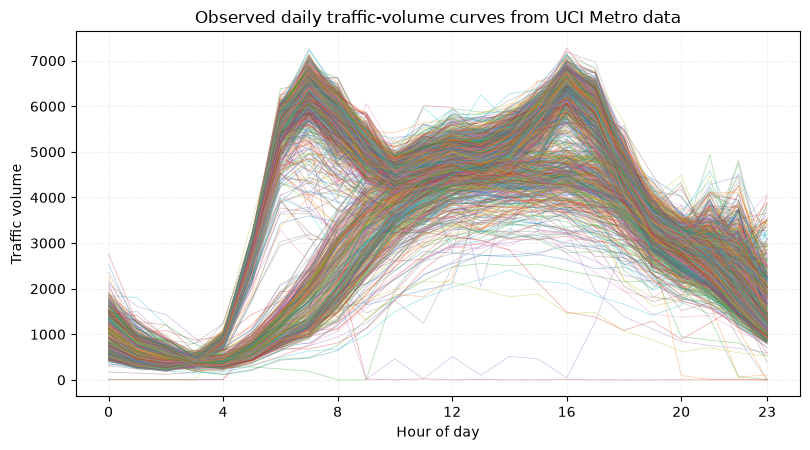

In [72]:
set_seed(CFG.seed)
device = torch.device("cpu")

print("\nLoading UCI Metro Interstate Traffic Volume hourly data...")
df_hour = load_hourly_traffic_dataframe(CFG)

s, x_counts, y_raw, y_feature_names, dates = build_daily_functional_and_nonfunctional_data(
    df_hour
)

if x_counts.shape[0] <= CFG.forecast_horizon + 65:
    raise ValueError("Not enough complete days for the requested forecast horizon.")

L = CFG.forecast_horizon
baseline_k = CFG.latent_dim if CFG.baseline_latent_dim is None else CFG.baseline_latent_dim

# Functional curves are modeled on standardized log1p count scale.
x_log = np.log1p(x_counts).astype(np.float32)

x_train_log_full = x_log[:-L]
x_test_counts = x_counts[-L:]
x_test_log = x_log[-L:]

y_train_raw_full = y_raw[:-L]
y_test_raw = y_raw[-L:]
test_dates = dates[-L:]

# Fit scalers only on pre-forecast observations.
x_log_scaler = StandardScaler()
x_train_standardized_log_full = x_log_scaler.fit_transform(x_train_log_full).astype(np.float32)
x_test_standardized_log = x_log_scaler.transform(x_test_log).astype(np.float32)

y_scaler = StandardScaler()
y_train_scaled_full = y_scaler.fit_transform(y_train_raw_full).astype(np.float32)
y_test_scaled = y_scaler.transform(y_test_raw).astype(np.float32)

print(f"Total hourly rows in Metro CSV:       {len(df_hour)}")
print(f"Complete daily functional curves:     {x_counts.shape[0]}")
print(f"Pre-forecast daily observations:      {x_train_standardized_log_full.shape[0]}")
print(f"Forecast/test observations:           {L}")
print(f"Forecast/test date range:             {test_dates[0].date()} to {test_dates[-1].date()}")
print(f"Functional curves shape:              {x_counts.shape}")
print(f"Nonfunctional matrix shape:           {y_raw.shape}")
print(f"Shared latent dimension K:            {CFG.latent_dim}")
print(f"HPCA/FPCA score dimension K:          {baseline_k}")

output_dir = Path("plots")
output_dir.mkdir(parents=True, exist_ok=True)

plot_observed_curves(
    s=s,
    x_counts=x_counts,
    title="Observed daily traffic-volume curves from UCI Metro data",
    save_path=output_dir / "observed_daily_traffic_curves.pdf",
)


## Train HAE and forecast latent scores


Training tuned Hybrid AE with chronological validation split...
Epoch    1/900  | train_func=0.820233 | val_func=0.173266 | train_nonfunc=0.908394 | val_nonfunc=0.596893
Epoch   50/900* | train_func=0.258616 | val_func=0.108005 | train_nonfunc=0.252023 | val_nonfunc=0.313342
Epoch  100/900* | train_func=0.122782 | val_func=0.116890 | train_nonfunc=0.129211 | val_nonfunc=0.331089
Epoch  150/900* | train_func=0.098020 | val_func=0.126536 | train_nonfunc=0.097063 | val_nonfunc=0.270307
Epoch  200/900* | train_func=0.083162 | val_func=0.098348 | train_nonfunc=0.078115 | val_nonfunc=0.267499
Epoch  250/900* | train_func=0.083897 | val_func=0.095236 | train_nonfunc=0.078435 | val_nonfunc=0.261171
Epoch  300/900* | train_func=0.069036 | val_func=0.096010 | train_nonfunc=0.062174 | val_nonfunc=0.271532
Epoch  350/900* | train_func=0.068856 | val_func=0.120332 | train_nonfunc=0.057373 | val_nonfunc=0.256618
Epoch  400/900* | train_func=0.066440 | val_func=0.095454 | train_nonfunc=0.054427 | va

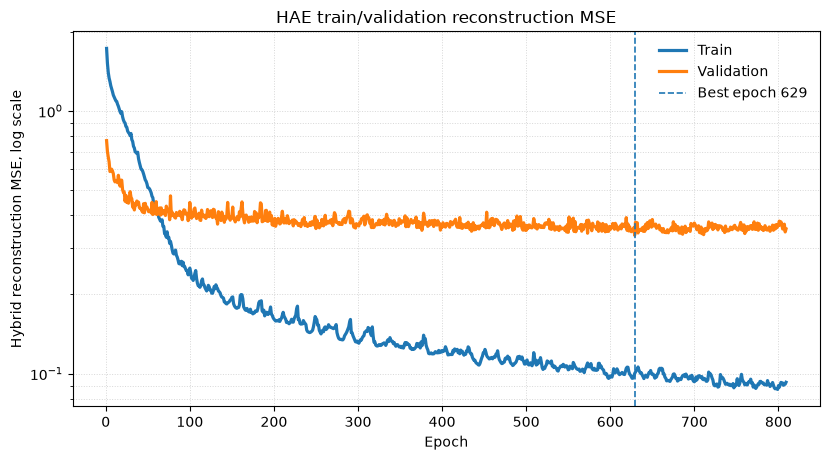


HAE reconstruction MSE on full pre-forecast block
Functional standardized log1p-count scale: 0.066398
Nonfunctional standardized scale:          0.073537

Fitting external VAR model to HAE latent scores...
HAE score model: VAR(7)
HAE score AIC:   -1.805129


In [73]:
# --------------------------------------------------------
# 1. HAE + VAR
# --------------------------------------------------------
hybrid_model, history, refit_history = train_one_tuned_hybrid_model(
    cfg=CFG,
    x_train_full=x_train_standardized_log_full,
    y_train_full=y_train_scaled_full,
    s=s,
    device=device,
)

plot_training_validation_losses(history, CFG)

(
    x_recon_train_hybrid,
    y_recon_train_hybrid_scaled,
    H_train_torch,
    _,
    hybrid_functional_recon_mse,
    hybrid_nonfunctional_recon_mse,
) = predict_hybrid_ae(
    hybrid_model,
    torch.tensor(x_train_standardized_log_full, dtype=torch.float32),
    torch.tensor(y_train_scaled_full, dtype=torch.float32),
    device,
)

H_train = H_train_torch.detach().cpu().numpy()

print("\nHAE reconstruction MSE on full pre-forecast block")
print(f"Functional standardized log1p-count scale: {hybrid_functional_recon_mse:.6f}")
print(f"Nonfunctional standardized scale:          {hybrid_nonfunctional_recon_mse:.6f}")

print("\nFitting external VAR model to HAE latent scores...")
H_forecast, hybrid_forecast_info, _ = forecast_scores_time_series(
    H_train,
    L,
    CFG.max_ar_lags,
)

print(
    f"HAE score model: "
    f"{hybrid_forecast_info['model']}({hybrid_forecast_info['lag']})"
)
print(f"HAE score AIC:   {hybrid_forecast_info['aic']:.6f}")

hybrid_model.eval()
with torch.no_grad():
    H_forecast_torch = torch.tensor(H_forecast, dtype=torch.float32).to(device)
    (
        x_hybrid_forecast_standardized_log_torch,
        _,
        y_hybrid_forecast_scaled_torch,
    ) = hybrid_model.decode_latent(H_forecast_torch)

    x_hybrid_forecast_standardized_log = (
        x_hybrid_forecast_standardized_log_torch.detach().cpu().numpy()
    )
    y_hybrid_forecast_scaled = (
        y_hybrid_forecast_scaled_torch.detach().cpu().numpy()
    )

x_hybrid_forecast_counts = inverse_standardized_log_count_transform(
    x_hybrid_forecast_standardized_log,
    x_log_scaler,
)


## Fit HPCA and forecast

In [83]:
# --------------------------------------------------------
# 2. HPCA + VAR: hybrid PCA on [functional, nonfunctional]
# --------------------------------------------------------
print("\nFitting HPCA baseline on concatenated functional + nonfunctional variables...")
hpca_out = concatenated_fpca_pca_forecast(
    x_train_standardized_log=x_train_standardized_log_full,
    y_train_scaled=y_train_scaled_full,
    horizon=L,
    latent_dim=baseline_k,
    maxlags=CFG.max_ar_lags,
)

x_hpca_forecast_standardized_log = hpca_out["x_forecast_standardized_log"]
x_hpca_forecast_counts = inverse_standardized_log_count_transform(
    x_hpca_forecast_standardized_log,
    x_log_scaler,
)
y_hpca_forecast_scaled = hpca_out["y_forecast_scaled"]

print(
    f"HPCA score model: "
    f"{hpca_out['forecast_info']['model']}({hpca_out['forecast_info']['lag']})"
)
print(f"HPCA score AIC:   {hpca_out['forecast_info']['aic']:.6f}")
print(f"HPCA explained variance with K={baseline_k}: {np.sum(hpca_out['pca'].explained_variance_ratio_):.4f}")


print("\nHPCA reconstruction MSE on full pre-forecast block")
print(f"Functional standardized log1p-count scale: {mse(hpca_out['x_recon_train_standardized_log'], x_train_standardized_log_full):.6f}")
print(f"Nonfunctional standardized scale:          {mse(hpca_out['y_recon_train_scaled'], y_train_scaled_full):.6f}")


hpca_f = mse(
    hpca_out["x_recon_train_standardized_log"],
    x_train_standardized_log_full
)
hpca_n = mse(
    hpca_out["y_recon_train_scaled"],
    y_train_scaled_full
)

for name, hpca, hae in [
    ("Functional", hpca_f, hybrid_functional_recon_mse),
    ("Nonfunctional", hpca_n, hybrid_nonfunctional_recon_mse),
    ("Combined", hpca_f + hpca_n,
     hybrid_functional_recon_mse + hybrid_nonfunctional_recon_mse),
]:
    print(f"{name}: HPCA={hpca:.4f}, HAE={hae:.4f}, "
          f"Reduction={100*(hpca-hae)/hpca:.2f}%")




Fitting HPCA baseline on concatenated functional + nonfunctional variables...
HPCA score model: VAR(12)
HPCA score AIC:   -4.108499
HPCA explained variance with K=5: 0.4862

HPCA reconstruction MSE on full pre-forecast block
Functional standardized log1p-count scale: 0.191958
Nonfunctional standardized scale:          0.608483
Functional: HPCA=0.1920, HAE=0.0664, Reduction=65.41%
Nonfunctional: HPCA=0.6085, HAE=0.0735, Reduction=87.91%
Combined: HPCA=0.8004, HAE=0.1399, Reduction=82.52%


## Train and forecast functional-only FAE

In [75]:
# --------------------------------------------------------
# 3. FAE + VAR: functional-only nonlinear model
# --------------------------------------------------------
fae_model, fae_history = train_fae_model(
    cfg=CFG,
    x_train_full=x_train_standardized_log_full,
    s=s,
    device=device,
)

fae_out = forecast_fae_from_trained_model(
    fae_model=fae_model,
    x_train_standardized_log_full=x_train_standardized_log_full,
    horizon=L,
    cfg=CFG,
    x_log_scaler=x_log_scaler,
    device=device,
)

x_fae_forecast_counts = fae_out["x_forecast_counts"]
x_fae_forecast_standardized_log = fae_out["x_forecast_standardized_log"]



Training functional-only FAE...
FAE epoch    1/900  | train_func=0.717116 | val_func=0.110493
FAE epoch   50/900* | train_func=0.114875 | val_func=0.043900
FAE epoch  100/900* | train_func=0.053879 | val_func=0.048300
FAE epoch  150/900* | train_func=0.051290 | val_func=0.035822
FAE epoch  200/900* | train_func=0.054176 | val_func=0.037409
FAE epoch  250/900* | train_func=0.057782 | val_func=0.034033
FAE epoch  300/900* | train_func=0.045376 | val_func=0.102352
FAE epoch  350/900* | train_func=0.045547 | val_func=0.223399
FAE epoch  400/900* | train_func=0.043963 | val_func=0.071899
FAE early stopping at epoch 426. Best epoch=246, best val functional MSE=0.027716

Functional-only FAE reconstruction MSE on full pre-forecast block
Functional standardized log1p-count scale: 0.045222

Fitting external VAR model to functional-only FAE latent scores...
FAE score model: VAR(7)
FAE score AIC:   -2.435581


## Fit functional-only FPCA

In [76]:
# --------------------------------------------------------
# 4. FPCA + VAR: functional-only linear baseline
# --------------------------------------------------------
print("\nFitting functional-only FPCA baseline...")
fpca_out = functional_fpca_forecast(
    x_train_standardized_log=x_train_standardized_log_full,
    horizon=L,
    latent_dim=baseline_k,
    maxlags=CFG.max_ar_lags,
)

x_fpca_forecast_standardized_log = fpca_out["x_forecast_standardized_log"]
x_fpca_forecast_counts = inverse_standardized_log_count_transform(
    x_fpca_forecast_standardized_log,
    x_log_scaler,
)

print(
    f"FPCA score model: "
    f"{fpca_out['forecast_info']['model']}({fpca_out['forecast_info']['lag']})"
)
print(f"FPCA score AIC:   {fpca_out['forecast_info']['aic']:.6f}")
print(
    f"FPCA explained variance with K={fpca_out['latent_dim_used']}: "
    f"{fpca_out['explained_variance_ratio_sum']:.4f}"
)

fpca_recon_mse = mse(
    fpca_out["x_recon_train_standardized_log"],
    x_train_standardized_log_full,
)
print(f"FPCA reconstruction MSE on standardized log scale: {fpca_recon_mse:.6f}")



Fitting functional-only FPCA baseline...
FPCA score model: VAR(13)
FPCA score AIC:   -2.297203
FPCA explained variance with K=5: 0.9398
FPCA reconstruction MSE on standardized log scale: 0.060176


## Results

In [77]:
# --------------------------------------------------------
# Evaluation tables
# --------------------------------------------------------
all_functional_counts = {
    "HAE + VAR": x_hybrid_forecast_counts,
    "FAE + VAR": x_fae_forecast_counts,
    "HPCA + VAR": x_hpca_forecast_counts,
    "FPCA + VAR": x_fpca_forecast_counts,
}
all_functional_stdlog = {
    "HAE + VAR": x_hybrid_forecast_standardized_log,
    "FAE + VAR": x_fae_forecast_standardized_log,
    "HPCA + VAR": x_hpca_forecast_standardized_log,
    "FPCA + VAR": x_fpca_forecast_standardized_log,
}

functional_table = make_functional_forecast_table(
    method_forecasts_counts=all_functional_counts,
    method_forecasts_standardized_log=all_functional_stdlog,
    x_truth_counts=x_test_counts,
    x_truth_standardized_log=x_test_standardized_log,
)
print("\nFunctional forecast comparison: HAE, FAE, HPCA, FPCA")
print(functional_table.to_string(index=False, float_format=lambda v: f"{v:.6f}"))

fair_functional_table = make_functional_forecast_table(
    method_forecasts_counts={
        "FAE + VAR": x_fae_forecast_counts,
        "FPCA + VAR": x_fpca_forecast_counts,
    },
    method_forecasts_standardized_log={
        "FAE + VAR": x_fae_forecast_standardized_log,
        "FPCA + VAR": x_fpca_forecast_standardized_log,
    },
    x_truth_counts=x_test_counts,
    x_truth_standardized_log=x_test_standardized_log,
)
print("\nFunctional-only fair comparison: FAE vs FPCA")
print(fair_functional_table.to_string(index=False, float_format=lambda v: f"{v:.6f}"))
print_pairwise_functional_winner(
    table=fair_functional_table,
    method_a="FAE + VAR",
    method_b="FPCA + VAR",
    heading="FAE vs FPCA",
)

hybrid_table = make_hybrid_forecast_table(
    method_x_forecasts_standardized_log={
        "HAE + VAR": x_hybrid_forecast_standardized_log,
        "HPCA + VAR": x_hpca_forecast_standardized_log,
    },
    method_y_forecasts_scaled={
        "HAE + VAR": y_hybrid_forecast_scaled,
        "HPCA + VAR": y_hpca_forecast_scaled,
    },
    x_truth_standardized_log=x_test_standardized_log,
    y_truth_scaled=y_test_scaled,
)
print("\nHybrid forecast comparison: HAE vs HPCA")
print(hybrid_table.to_string(index=False, float_format=lambda v: f"{v:.6f}"))
print_pairwise_hybrid_winner(
    functional_table=functional_table,
    hybrid_table=hybrid_table,
    method_a="HAE + VAR",
    method_b="HPCA + VAR",
    heading="HAE vs HPCA",
)



Functional forecast comparison: HAE, FAE, HPCA, FPCA
    Method  Functional_MSE_count  Functional_RMSE_count  Functional_relMSE_count  Functional_MSE_stdlog  Functional_relMSE_stdlog
 HAE + VAR         356421.666557             597.010608                 0.023103               0.283086                  0.589819
 FAE + VAR         177441.996313             421.238645                 0.011502               0.172591                  0.359599
HPCA + VAR         558120.706334             747.074766                 0.036177               0.447868                  0.933147
FPCA + VAR         323829.124496             569.059860                 0.020990               0.214134                  0.446155

Functional-only fair comparison: FAE vs FPCA
    Method  Functional_MSE_count  Functional_RMSE_count  Functional_relMSE_count  Functional_MSE_stdlog  Functional_relMSE_stdlog
 FAE + VAR         177441.996313             421.238645                 0.011502               0.172591                 

In [90]:

# --------------------------------------------------------
# Nonfunctional reconstruction and forecast errors
# --------------------------------------------------------

# 16 weather summaries + 2 ranges + 2 occurrences = 20
cols = [
    f"{v}_{s}"
    for v in ["temp", "rain_1h", "snow_1h", "clouds_all"]
    for s in ["mean", "min", "max", "std"]
] + ["temp_range", "clouds_range", "rain_any", "snow_any"]

# Uncomment to include 9 weather-condition indicators (29 total)
cols += [f"weather_{w}" for w in [
    "Clear", "Clouds", "Rain", "Mist", "Snow",
    "Drizzle", "Haze", "Fog", "Thunderstorm"
]]

idx = [y_feature_names.index(c) for c in cols]


# Convert PyTorch tensors to NumPy arrays when needed
def to_numpy(x):
    return x.detach().cpu().numpy() if hasattr(x, "detach") else np.asarray(x)

# MSE for each selected variable
def mse_by_var(pred, truth):
    pred = to_numpy(pred)
    truth = to_numpy(truth)
    return np.mean((pred[:, idx] - truth[:, idx])**2, axis=0)

results = pd.DataFrame({
    "Variable": cols,
    "HAE_Recon": mse_by_var(
        y_recon_train_hybrid_scaled, y_train_scaled_full),
    "HPCA_Recon": mse_by_var(
        hpca_out["y_recon_train_scaled"], y_train_scaled_full),
    "HAE_Forecast": mse_by_var(
        y_hybrid_forecast_scaled, y_test_scaled),
    "HPCA_Forecast": mse_by_var(
        y_hpca_forecast_scaled, y_test_scaled),
})


print("\nNonfunctional MSE by variable:")
print(results.round(4).to_string(index=False))

print("\nAverage MSE across selected variables:")
print(results.iloc[:, 1:].mean().round(4))

print("\nHAE forecasting improvement (%):")
a = results["HAE_Forecast"].mean()
b = results["HPCA_Forecast"].mean()
print(f"{100 * (b - a) / b:.2f}%")



Nonfunctional MSE by variable:
            Variable  HAE_Recon  HPCA_Recon  HAE_Forecast  HPCA_Forecast
           temp_mean     0.0777      0.0717        0.4559         0.3485
            temp_min     0.0550      0.1711        0.2958         0.1738
            temp_max     0.0901      0.1053        0.4701         0.4668
            temp_std     0.0644      0.5791        0.0450         0.0875
        rain_1h_mean     0.0236      0.2212        0.0046         0.0029
         rain_1h_min     0.8762      0.9855        0.0015         0.0191
         rain_1h_max     0.0237      0.2240        0.0050         0.0027
         rain_1h_std     0.0237      0.2238        0.0048         0.0027
        snow_1h_mean     0.0001      0.0000        0.0000         0.0000
         snow_1h_min     0.0001      0.0000        0.0000         0.0000
         snow_1h_max     0.0001      0.0000        0.0000         0.0000
         snow_1h_std     0.0000      0.0000        0.0000         0.0000
     clouds_all_mea

In [78]:
# --------------------------------------------------------
# Forecast curve plots, all compact 2 x 4 when L = 7
# --------------------------------------------------------
# plot_forecast_curves_grid(
#     s=s,
#     observed_counts=x_test_counts,
#     method_forecasts_counts={
#         "HAE + VAR": x_hybrid_forecast_counts,
#         "FAE + VAR": x_fae_forecast_counts,
#         "HPCA + VAR": x_hpca_forecast_counts,
#         "FPCA + VAR": x_fpca_forecast_counts,
#     },
#     forecast_dates=test_dates,
#     title="Functional forecasts: HAE vs FAE vs HPCA vs FPCA",
#     ncols=4,
#     dense_points=CFG.dense_plot_points,
#     save_path=output_dir / "all_functional_forecasts.pdf",
# )

# plot_forecast_curves_grid(
#     s=s,
#     observed_counts=x_test_counts,
#     method_forecasts_counts={
#         "FAE + VAR": x_fae_forecast_counts,
#         "FPCA + VAR": x_fpca_forecast_counts,
#     },
#     forecast_dates=test_dates,
#     title="Functional-only comparison: FAE vs FPCA",
#     ncols=4,
#     dense_points=CFG.dense_plot_points,
#     save_path=output_dir / "fae_vs_fpca.pdf",
# )

#plot_forecast_curves_grid(
#    s=s,
#    observed_counts=x_test_counts,
#    method_forecasts_counts={
#        "HAE + VAR": x_hybrid_forecast_counts,
#        "HPCA + VAR": x_hpca_forecast_counts,
#    },
#    forecast_dates=test_dates,
#    title="Hybrid comparison on functional curves: HAE vs HPCA",
#    ncols=4,
#    dense_points=CFG.dense_plot_points,
#    save_path=output_dir / "hae_vs_hpca.pdf",
#)

# plot_hae_vs_hpca_paper(
#     hour_grid=s,
#     observed_counts=x_test_counts,
#     hae_forecast_counts=x_hybrid_forecast_counts,
#     hpca_forecast_counts=x_hpca_forecast_counts,
#     forecast_dates=test_dates,
#     dense_points=CFG.dense_plot_points,
#     save_path=output_dir / "hae_vs_hpca.pdf",
# )


## Plot: Observed vs. HPCA vs. HAE

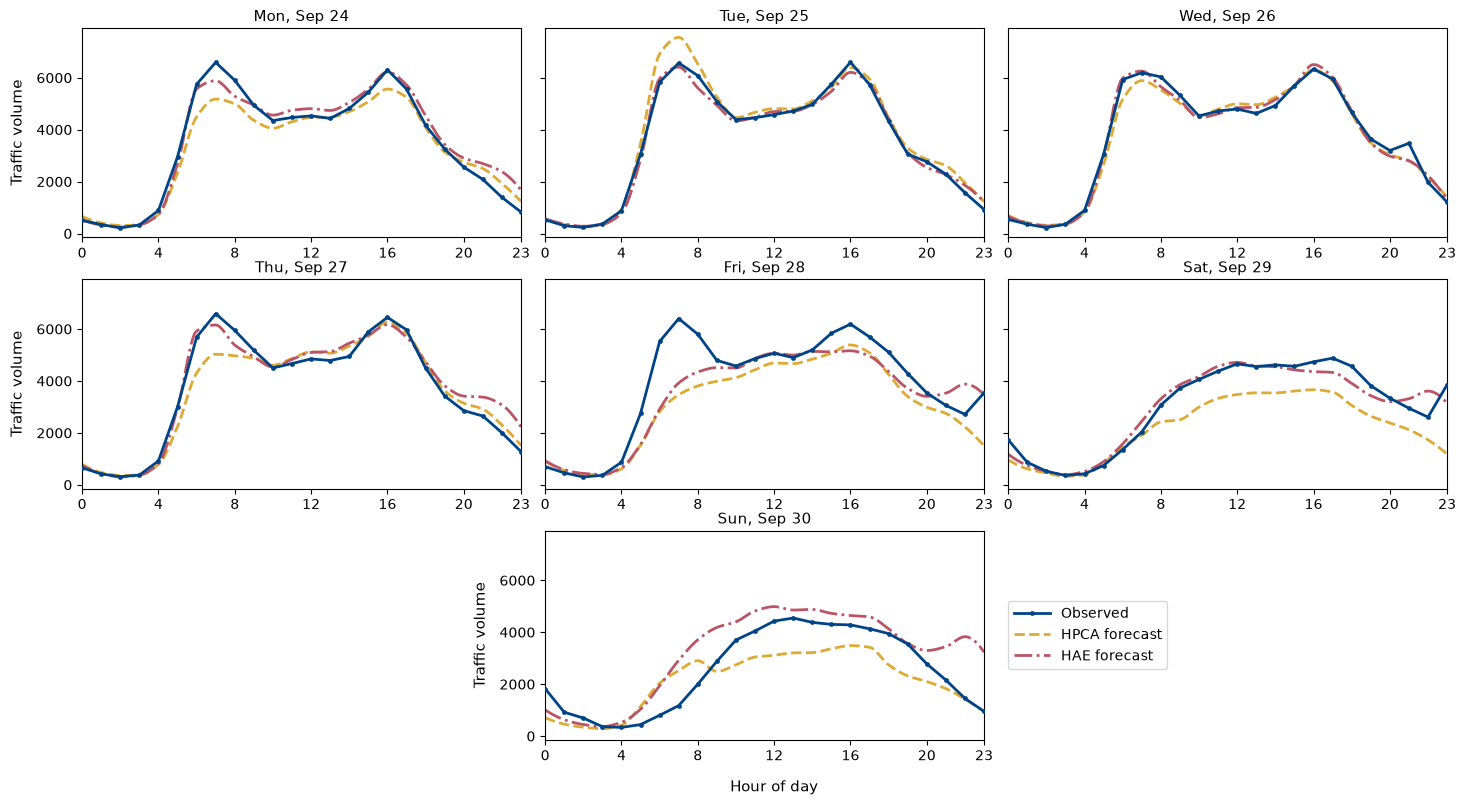

In [79]:
plot_hae_vs_hpca_paper(
    hour_grid=s,
    observed_counts=x_test_counts,
    hae_forecast_counts=x_hybrid_forecast_counts,
    hpca_forecast_counts=x_hpca_forecast_counts,
    forecast_dates=test_dates,
    dense_points=CFG.dense_plot_points,
    save_path=output_dir / "hae_vs_hpca.pdf",
)


In [80]:
# --------------------------------------------------------
# Horizon-level MSE plots
# --------------------------------------------------------
# plot_functional_mse_by_horizon(
#     truth_counts=x_test_counts,
#     method_forecasts_counts={
#         "HAE + VAR": x_hybrid_forecast_counts,
#         "FAE + VAR": x_fae_forecast_counts,
#         "HPCA + VAR": x_hpca_forecast_counts,
#         "FPCA + VAR": x_fpca_forecast_counts,
#     },
#     title="Functional count-scale MSE by horizon: HAE vs FAE vs HPCA vs FPCA",
# )

# plot_functional_mse_by_horizon(
#     truth_counts=x_test_counts,
#     method_forecasts_counts={
#         "FAE + VAR": x_fae_forecast_counts,
#         "FPCA + VAR": x_fpca_forecast_counts,
#     },
#     title="Functional-only count-scale MSE by horizon: FAE vs FPCA",
# )

# plot_hybrid_standardized_mse_by_horizon(
#     x_truth_standardized_log=x_test_standardized_log,
#     y_truth_scaled=y_test_scaled,
#     method_x_forecasts_standardized_log={
#         "HAE + VAR": x_hybrid_forecast_standardized_log,
#         "HPCA + VAR": x_hpca_forecast_standardized_log,
#     },
#     method_y_forecasts_scaled={
#         "HAE + VAR": y_hybrid_forecast_scaled,
#         "HPCA + VAR": y_hpca_forecast_scaled,
#     },
#     title="Hybrid standardized MSE by horizon: HAE vs HPCA",
# )


In [81]:
# --------------------------------------------------------
# Nonfunctional visualization: bar plot + heatmap
# --------------------------------------------------------
# plot_nonfunctional_featurewise_rmse_bar(
#     truth_scaled=y_test_scaled,
#     method_forecasts_scaled={
#         "HAE + VAR": y_hybrid_forecast_scaled,
#         "HPCA + VAR": y_hpca_forecast_scaled,
#     },
#     feature_names=y_feature_names,
#     top_n=14,
#     title="Nonfunctional featurewise RMSE: HAE vs HPCA",
# )

# plot_nonfunctional_abs_error_heatmap(
#     truth_scaled=y_test_scaled,
#     method_forecasts_scaled={
#         "HAE + VAR": y_hybrid_forecast_scaled,
#         "HPCA + VAR": y_hpca_forecast_scaled,
#     },
#     feature_names=y_feature_names,
#     top_n=12,
#     title="Nonfunctional held-out magnitude and absolute forecast errors: HAE vs HPCA",
# )
